# EDA: PAD-UFES-20

**What this EDA has to answer for the project**

1. How is the data structured (patients / lesions / images) and how do we split it without leakage?
2. Which labels and metadata exist, how are they distributed, and how much is missing?
3. Which metadata features are informative, which are weak, and which are shortcuts (label leakage)?
4. What do the images look like (sizes, colour modes, artefacts such as marker rings), and what must be standardised?
5. How coarse will per-class (especially MEL) uncertainty statistics be under patient-grouped 5-fold CV?

**Repository layout expected by this notebook**

```
eda/
|-- data/
|   |-- metadata.csv
|   |-- imgs_part_1/   (PNG images)
|   |-- imgs_part_2/
|   `-- imgs_part_3/
`-- notebooks/
    `-- exploratory_data_analysis.ipynb      <- this file (run it from inside notebook/)
```

Figures are also written to `notebook/figures/`. Required packages: `numpy pandas matplotlib seaborn scipy scikit-learn pillow`.

| Level | Definition | Count |
|---|---|---|
| image | one row of `metadata.csv` | 2,298 |
| lesion | unique `(patient_id, lesion_id)` pair - `lesion_id` alone is **not** unique (Section 1) | 1,891 |
| patient | unique `patient_id` | 1,373 |

In [40]:
%pip install scikit-learn
import warnings, glob, os, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from scipy.stats import chi2_contingency, kruskal
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)

DATA = Path("../data")            # repo layout: notebook/ next to data/
FIG_DIR = Path("../figures") 
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

ORDER = ["BCC", "ACK", "NEV", "SEK", "SCC", "MEL"]          # sorted by frequency
PAL = dict(zip(ORDER, sns.color_palette("Set2", 6)))
MALIGNANT = ["BCC", "SCC", "MEL"]

def finish(name):
    """tight layout, save to figures/ and show"""
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

Note: you may need to restart the kernel to use updated packages.


In [41]:
# raw strings (exact comparisons) and parsed data ("UNK" is treated as missing)
raw = pd.read_csv(DATA / "metadata.csv", keep_default_na=False, dtype=str)
df = pd.read_csv(DATA / "metadata.csv").replace({"UNK": np.nan})

# feature groups: 22 clinical features + 3 identifiers + 1 label = 26 columns
ID_COLS = ["patient_id", "lesion_id", "img_id"]
LABEL = "diagnostic"
BIN = ["smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history", "has_piped_water", "has_sewage_system",
       "itch", "grew", "hurt", "changed", "bleed", "elevation", "biopsed"]
CAT = ["gender", "region", "background_father", "background_mother"]
NUM = ["age", "diameter_1", "diameter_2", "fitspatrick"]       # fitspatrick = ordinal skin type 1-6
FEATS = BIN + CAT + NUM
assert len(FEATS) + len(ID_COLS) + 1 == raw.shape[1] == 26, "unexpected column set"

df["has_clinical"] = df["smoke"].notna()                       # the questionnaire block is missing jointly (Section 5)
df["patient_num"] = df.patient_id.str.extract(r"(\d+)")[0].astype(int)
lesions = df.drop_duplicates(["patient_id", "lesion_id"]).copy()   # one row per lesion
print("columns:", raw.shape[1], "| rows (images):", len(df), "| lesions:", len(lesions), "| patients:", df.patient_id.nunique())
df.head()

columns: 26 | rows (images): 2298 | lesions: 1891 | patients: 1373


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,cancer_history,has_piped_water,has_sewage_system,fitspatrick,region,diameter_1,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed,has_clinical,patient_num
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ARM,NaN,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False,False,1516
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,True,True,True,3.0,NECK,6.0,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True,True,46
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FACE,NaN,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False,False,1545
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HAND,NaN,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False,False,1989
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,False,False,False,1.0,FOREARM,5.0,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True,True,684


## 1. Dataset structure: patients, lesions, images

**Description:**
- PAD-UFES-20: smartphone photos of skin lesions with patient/lesion metadata (Federal University of Espirito Santo, Brazil). Each row of `metadata.csv` is **one image** (not one lesion).
- 26 columns: 3 identifiers (`patient_id`, `lesion_id`, `img_id`), 1 label (`diagnostic`) and 22 clinical features (incl. `biopsed`).
- A patient can have several lesions and a lesion can have several images
- The dataset paper states 1,641 lesions; the data suggests 1,891. The cell below resolves this.

In [42]:
pairs = df[["patient_id", "lesion_id"]].drop_duplicates()
shared = pairs.groupby("lesion_id").patient_id.nunique()          # how many patients use a given lesion_id
summary = pd.Series({
    "images (rows)": len(df),
    "patients": df.patient_id.nunique(),
    "distinct lesion_id values": df.lesion_id.nunique(),
    "distinct (patient_id, lesion_id) pairs = lesions": len(pairs),
    "lesion_id values used by >1 patient": int((shared > 1).sum()),
}).to_frame("value")
display(summary)

# are the colliding lesion_ids "the same lesion"? compare age, diagnosis and region of the patients sharing the id
g = raw[raw.lesion_id.isin(shared[shared > 1].index.astype(str))].drop_duplicates(["patient_id", "lesion_id"])
chk = g.groupby("lesion_id").agg(age=("age", "nunique"), dx=("diagnostic", "nunique"), reg=("region", "nunique"))
same = int(((chk.age == 1) & (chk.dx == 1) & (chk.reg == 1)).sum())
print(f"colliding lesion_ids: {len(chk)} | of these where age, diagnosis AND region agree: {same}")

,value
images (rows),2298
patients,1373
distinct lesion_id values,1641
"distinct (patient_id, lesion_id) pairs = lesions",1891
lesion_id values used by >1 patient,250


colliding lesion_ids: 250 | of these where age, diagnosis AND region agree: 0


,mean,median,max,n with more than 1,share with more than 1 (%)
images per lesion,1.22,1.0,6,361,19.09
lesions per patient,1.38,1.0,8,355,25.86
images per patient,1.67,1.0,10,544,39.62


lesions with 1 image: 1530 | lesions with >1 image: 361 -> images in those multi-image lesions: 768


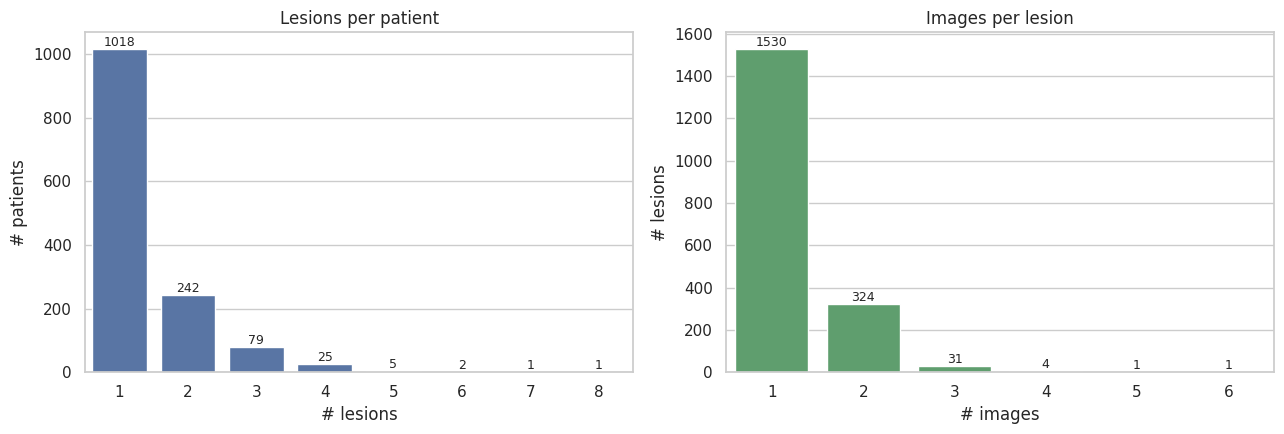

In [44]:
per_les = df.groupby(["patient_id", "lesion_id"]).size()           # images per lesion
les_per_pat = pairs.groupby("patient_id").size()                   # lesions per patient
img_per_pat = df.groupby("patient_id").size()                      # images per patient

stats = pd.DataFrame({
    "mean": [per_les.mean(), les_per_pat.mean(), img_per_pat.mean()],
    "median": [per_les.median(), les_per_pat.median(), img_per_pat.median()],
    "max": [per_les.max(), les_per_pat.max(), img_per_pat.max()],
    "n with more than 1": [(per_les > 1).sum(), (les_per_pat > 1).sum(), (img_per_pat > 1).sum()],
    "share with more than 1 (%)": [100 * (per_les > 1).mean(), 100 * (les_per_pat > 1).mean(), 100 * (img_per_pat > 1).mean()],
}, index=["images per lesion", "lesions per patient", "images per patient"]).round(2)
display(stats)
print("lesions with 1 image:", int((per_les == 1).sum()), "| lesions with >1 image:", int((per_les > 1).sum()),
      "-> images in those multi-image lesions:", int(per_les[per_les > 1].sum()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x=les_per_pat.values, ax=ax[0], color="#4c72b0"); ax[0].set(title="Lesions per patient", xlabel="# lesions", ylabel="# patients")
sns.countplot(x=per_les.values, ax=ax[1], color="#55a868"); ax[1].set(title="Images per lesion", xlabel="# images", ylabel="# lesions")
for a in ax:
    for c in a.containers: a.bar_label(c, fontsize=9)
finish("01_structure_samples")

**Findings:**
- 2,298 images, 1,373 patients, **1,641 distinct `lesion_id` values** but **1,891 distinct `(patient_id, lesion_id)` pairs**, images as independent overstates the sample size
- 250 `lesion_id` values are used by two different patients. In none of these 250 cases do age, diagnosis and body region agree -> they are **different lesions that share a number**, not duplicates. (e.g. PAT_934_1778_140.png, PAT_1521_1778_763.png)
- The paper reports 1,641 lesions, which equals the number of distinct `lesion_id` values; the ISIC archive lists the same dataset with 1,891 lesions. We cannot know how the authors counted; the raw data supports **1,891 lesions**.
- 1,530 lesions have a single image; **361 lesions (19.1 %) have 2-6 images** (768 images in total).
- Lesions per patient: mean 1.38, **355 patients (25.9 %) have more than one lesion** (max. 8). Images per patient: mean 1.67, max. 10.
- Most lesions/patients appear only once; the repeated ones are nevertheless enough to cause leakage.

**Potential consequences for model training:**
- **grouped by `patient_id`, stratified by the lesion's diagnosis** (patient-grouped 5-fold CV, e.g. `StratifiedGroupKFold`) to prevent patient-specific information leakage and ensure reliable evaluation on previously unseen patients.

## 2. Class distribution

**Description:**
- 6 diagnostic classes: 3 skin cancers (BCC, SCC, MEL) and 3 skin diseases (ACK, NEV, SEK).
- plots show class imbalance at image level and how it changes at lesion and patient level (the effective sample size for rare classes).

,images,share_%,lesions,patients
diagnostic,,,,
BCC,845,36.8,652,513
ACK,730,31.8,644,525
NEV,244,10.6,216,185
SEK,235,10.2,198,176
SCC,192,8.4,145,133
MEL,52,2.3,36,36


imbalance ratio max/min (images): 16.2 : 1


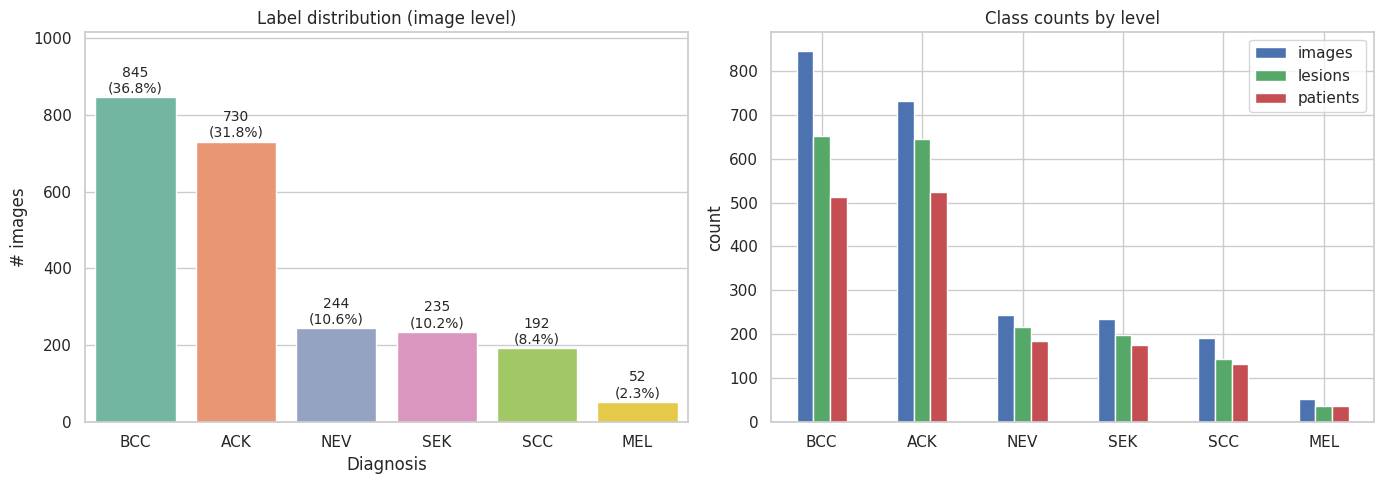

In [45]:
vc = df[LABEL].value_counts().reindex(ORDER)
tab = pd.DataFrame({"images": vc, "share_%": (100 * vc / vc.sum()).round(1)})
tab["lesions"] = lesions[LABEL].value_counts().reindex(ORDER)
tab["patients"] = df.groupby(LABEL).patient_id.nunique().reindex(ORDER)   # a patient may appear in several classes
display(tab)
print("imbalance ratio max/min (images): %.1f : 1" % (vc.max() / vc.min()))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=vc.index, y=vc.values, palette=[PAL[k] for k in vc.index], ax=ax[0])
for i, v in enumerate(vc.values): ax[0].text(i, v + 12, f"{v}\n({v/vc.sum():.1%})", ha="center", fontsize=10)
ax[0].set(title="Label distribution (image level)", xlabel="Diagnosis", ylabel="# images", ylim=(0, vc.max() * 1.2))
tab[["images", "lesions", "patients"]].plot(kind="bar", ax=ax[1], color=["#4c72b0", "#55a868", "#c44e52"], rot=0)
ax[1].set(title="Class counts by level", xlabel="", ylabel="count")
finish("02_label_distribution")

**Findings:**
- BCC 845 (36.8 %), ACK 730 (31.8 %), NEV 244 (10.6 %), SEK 235 (10.2 %), SCC 192 (8.4 %), **MEL 52 (2.3 %)**.
- Imbalance ratio **16.2 : 1** (BCC : MEL) -> strongly imbalanced.
- At lesion/patient level the rare classes shrink further: **MEL has only 36 lesions from 36 patients** (52 images), SCC 145 lesions / 133 patients.

**Potential consequences for model training:**
- Evaluation: **Macro-F1/AUC and balanced accuracy** instead of plain accuracy
- Training: class weighting, oversampling of minority classes and/or dynamic focal loss for MEL(paper1), data augmentation.
- Uncertainty: evaluate $\Delta U_{epi}$ **separately per class**; MEL estimates will be coarse (see Section 14) and should not be interpreted as precise.

## 3. Label and metadata consistency within lesion / patient

**Description:**
- Do images of the same lesion always carry the same diagnosis and the same metadata (everything except `img_id`)?
- Can a patient have several diagnoses? This decides how a patient-level label would have to be defined and whether stratification by patient is exact.

In [46]:
n_diag_pat = df.groupby("patient_id")[LABEL].nunique()
n_diag_les = df.groupby(["patient_id", "lesion_id"])[LABEL].nunique()
print("patients with >1 diagnosis:", int((n_diag_pat > 1).sum()), "| lesions with >1 diagnosis:", int((n_diag_les > 1).sum()))

# rows sharing (patient_id, lesion_id): is every column except img_id identical? (raw strings, so UNK/empty count as values)
key = ["patient_id", "lesion_id"]
size = raw.groupby(key).size(); multi = size[size > 1].index
sub = raw.set_index(key).loc[multi].reset_index()
cols = [c for c in raw.columns if c not in key + ["img_id"]]
diff = sub.groupby(key)[cols].nunique() > 1                      # True = column differs inside the group
print(f"multi-image lesions: {len(multi)} ({len(sub)} images) | group sizes: {size[size > 1].value_counts().sort_index().to_dict()}")
print("groups with at least one differing column (excluding img_id):", int(diff.any(axis=1).sum()))

patients with >1 diagnosis: 179 | lesions with >1 diagnosis: 0
multi-image lesions: 361 (768 images) | group sizes: {2: 324, 3: 31, 4: 4, 5: 1, 6: 1}
groups with at least one differing column (excluding img_id): 0


**Findings:**
- **0 of 1,891 lesions** have more than one diagnosis.
- **179 of 1,373 patients** have lesions with different diagnoses.
- In all **361 multi-image lesions (768 images)** every column except `img_id` is identical (0 differing columns, incl. all questionnaire fields and missingness).

**Potential consequences for model training:**
- For modality 2, images of one lesion are **exact metadata duplicates** - patient-level split or the same metadata tuple and label leak across the split.
- Labels are well-defined per lesion; a patient-level label is not (179 patients with mixed diagnoses) -> stratify with the lesion label, but **group by patient**.
- No conflicting entries exist inside a lesion, so no cleaning/consolidation step is required.

## 4. Missing values (overview)

**Description:**
- Which metadata are missing, and how much? (`UNK` and empty entries are both treated as missing.)
- Imputation values must later be fitted **inside each training fold** only; no information from the test fold may be used.

,missing_%
background_father,39.7
background_mother,39.4
smoke,35.0
drink,35.0
diameter_2,35.0
diameter_1,35.0
gender,35.0
fitspatrick,35.0
has_sewage_system,35.0
has_piped_water,35.0


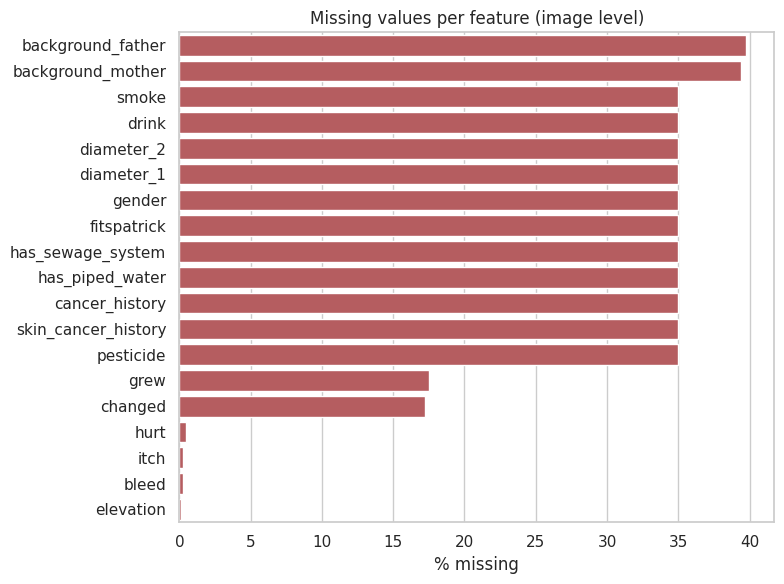

In [47]:
miss = (100 * df[FEATS].isna().mean()).sort_values(ascending=False)
display(miss[miss > 0].round(1).to_frame("missing_%"))
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=miss[miss > 0].values, y=miss[miss > 0].index, color="#c44e52", ax=ax)
ax.set(title="Missing values per feature (image level)", xlabel="% missing", ylabel="")
finish("03_missing_values")

**Findings:**
- **Questionnaire block:** 11 features (`smoke`, `drink`, `pesticide`, `skin_cancer_history`, `cancer_history`, `has_piped_water`, `has_sewage_system`, `gender`, `diameter_1`, `diameter_2`, `fitspatrick`) are missing **together for exactly the same 35.0 % of images**; `background_father/mother` miss 39-40 % (the same block plus ~4-5 % of individually missing entries).
- `grew` / `changed` miss 17.5 % / 17.2 %. The symptoms `itch`, `hurt`, `bleed`, `elevation` and the features `age`, `region`, `biopsed` are (almost) complete.

**Potential consequences for model training:**

## 5. Missingness per diagnosis class

**Description:**
- Does missingness depend on the diagnosis? If yes, a model can exploit "value missing" as a shortcut, and imputation can leak the label.
- Is the missing block tied to the patient-ID range (data-collection batch)?

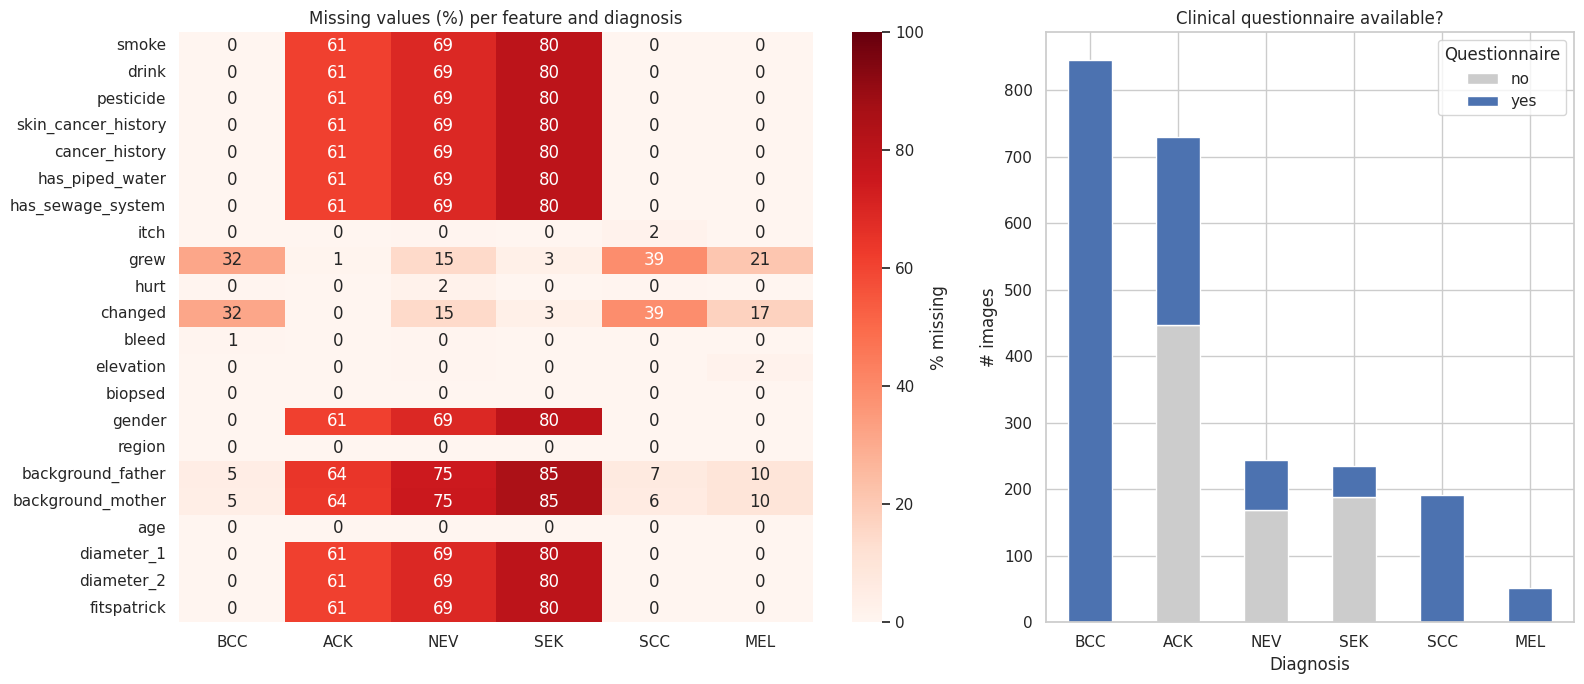

has_clinical,no questionnaire,questionnaire
diagnostic,,
BCC,0.000,1.000
ACK,0.612,0.388
NEV,0.693,0.307
SEK,0.800,0.200
SCC,0.000,1.000
MEL,0.000,1.000


In [48]:
mc = (100 * df[FEATS].isna().groupby(df[LABEL]).mean()).reindex(ORDER).T.round(1)
fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(mc, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, ax=ax[0], cbar_kws={"label": "% missing"})
ax[0].set(title="Missing values (%) per feature and diagnosis", ylabel="", xlabel="")
ct = pd.crosstab(df[LABEL], df.has_clinical).reindex(ORDER)
ct.plot(kind="bar", stacked=True, ax=ax[1], color=["#cccccc", "#4c72b0"], rot=0)
ax[1].set(title="Clinical questionnaire available?", xlabel="Diagnosis", ylabel="# images"); ax[1].legend(["no", "yes"], title="Questionnaire")
finish("04_missingness_by_class")
display(pd.crosstab(df[LABEL], df.has_clinical, normalize="index").round(3).reindex(ORDER).rename(columns={False: "no questionnaire", True: "questionnaire"}))

images WITHOUT questionnaire: 804 | lowest patient number among them: 996
highest patient number with BCC/SCC/MEL: 995
images from patients >= 996: 804 | classes: {'ACK': 447, 'SEK': 188, 'NEV': 169} | with questionnaire: 0


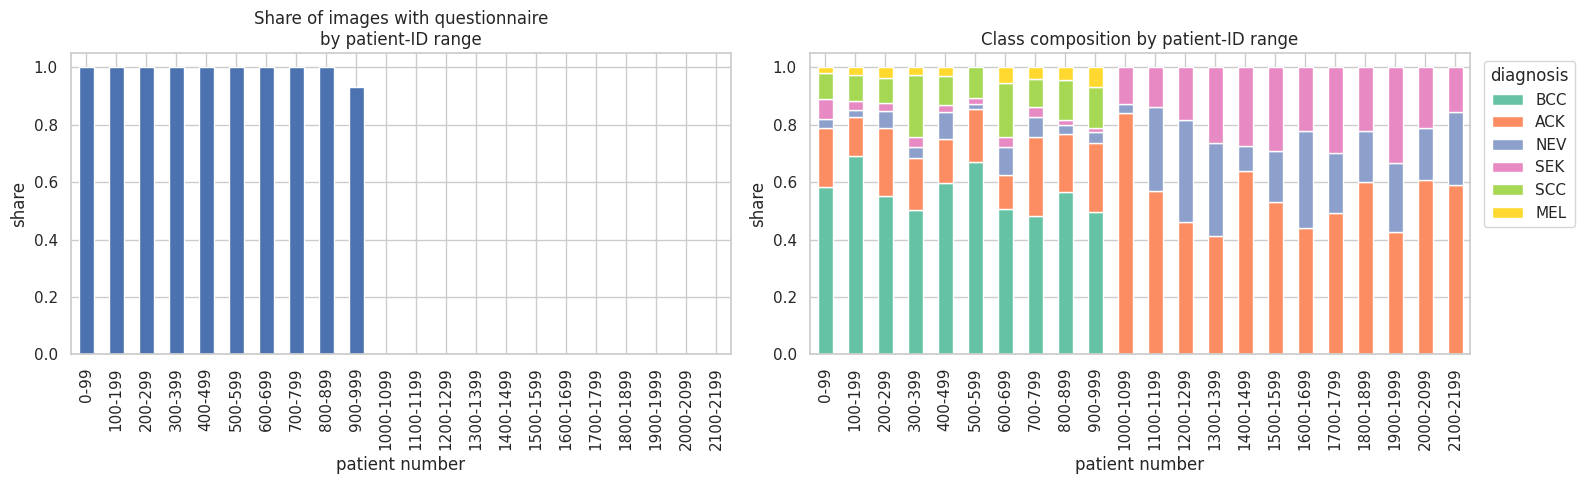

In [49]:
# is the questionnaire tied to the patient-ID range (collection batch)?
no_q = df[~df.has_clinical]
mal = df[LABEL].isin(MALIGNANT)
print(f"images WITHOUT questionnaire: {len(no_q)} | lowest patient number among them: {no_q.patient_num.min()}")
print(f"highest patient number with BCC/SCC/MEL: {df[mal].patient_num.max()}")
late = df[df.patient_num >= no_q.patient_num.min()]
print(f"images from patients >= {no_q.patient_num.min()}: {len(late)} | classes: {late[LABEL].value_counts().to_dict()} | with questionnaire: {int(late.has_clinical.sum())}")

bins = list(range(0, df.patient_num.max() + 100, 100)); lab = [f"{b}-{b+99}" for b in bins[:-1]]
df["pid_bin"] = pd.cut(df.patient_num, bins=bins, labels=lab, right=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
df.groupby("pid_bin", observed=True).has_clinical.mean().plot(kind="bar", ax=ax[0], color="#4c72b0")
ax[0].set(title="Share of images with questionnaire\nby patient-ID range", ylabel="share", xlabel="patient number")
cc = pd.crosstab(df.pid_bin, df[LABEL])[ORDER]
cc.div(cc.sum(axis=1), axis=0).plot(kind="bar", stacked=True, ax=ax[1], color=[PAL[k] for k in ORDER])
ax[1].set(title="Class composition by patient-ID range", ylabel="share", xlabel="patient number")
ax[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), title="diagnosis")
finish("05_questionnaire_vs_patient_id")

**Findings:**
- The questionnaire is available for **100 % of BCC, SCC and MEL** images but only for **38.8 % of ACK, 30.7 % of NEV and 20.0 % of SEK**.
- All **804 images without questionnaire** (35.0 %) come from patients numbered **>= 996**; none of the images from those patients has a questionnaire. Their classes are only ACK (447), SEK (188) and NEV (169) - **no malignant class**. The highest patient number with BCC/SCC/MEL is 995.
- So the missingness is a **collection batch** (patient-ID range) that contains no malignant cases. Within the benign classes the questionnaire is missing for the later batch, not at random.
- `grew` and `changed` are additionally missing for 31.5 % of BCC and 39.1 % of SCC (and 14.8 % of NEV) - class-dependent as well.

**Potential consequences for model training:**
- **Missingness is informative:** a model can learn "questionnaire missing -> benign class" as a shortcut. This can change the estimated uncertainty with metadata *without* the metadata content contributing anything.
- Impute **inside each training fold** (median for numeric features; `unknown` category for categorical ones - "no family history" is not the same as "history unknown", paper1).
- Treat **missing indicators as a separate experimental arm** (with vs. without) rather than hiding the pattern in imputation (see baseline, Section 12).
- Keep the patient-ID number out of the features (it encodes the batch), also lesion_id and img_id

## 6. `biopsed`: label leakage check

**Description:**
- `biopsed` says whether the diagnosis was confirmed by biopsy. The paper states that all skin cancers are biopsy-proven.
- How is `biopsed` distributed overall and within each class, and how strongly does it relate to the label?

overall: {True: 1342, False: 956}


count       row %       
biopsed    False True  False  True 
diagnostic                         
BCC            0   845   0.0  100.0
ACK          552   178  75.6   24.4
NEV          184    60  75.4   24.6
SEK          220    15  93.6    6.4
SCC            0   192   0.0  100.0
MEL            0    52   0.0  100.0

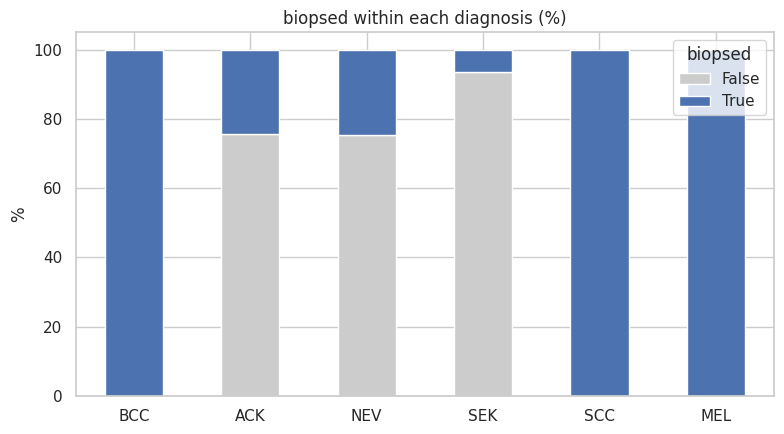

In [50]:
bt = pd.crosstab(df[LABEL], df.biopsed).reindex(ORDER)
btp = (100 * bt.div(bt.sum(axis=1), axis=0)).round(1)
print("overall:", df.biopsed.value_counts().to_dict())
display(pd.concat({"count": bt, "row %": btp}, axis=1))
btp.plot(kind="bar", stacked=True, figsize=(8, 4.5), color=["#cccccc", "#4c72b0"], rot=0)
plt.title("biopsed within each diagnosis (%)"); plt.ylabel("%"); plt.xlabel(""); plt.legend(["False", "True"], title="biopsed")
finish("06_biopsed_by_class")

**Findings:**
- Overall 1,342 images are biopsed, 956 are not.
- **BCC, SCC and MEL: 100 % biopsed** (845 / 192 / 52 images). ACK 24.4 %, NEV 24.6 %, SEK 6.4 %.
- `biopsed` has the **strongest association with the diagnosis of all features (Cramer's V = 0.80, Section 10)**.

**Potential consequences for model training:**
- `biopsed = True` is a near-certain hint for BCC/SCC/MEL: using it as an input would be **label leakage / a shortcut**, and it is not available at the point of care. **Exclude `biopsed`**
- The tabular baseline (Section 12) shows how little it adds on top of the other features (balanced accuracy 0.67 vs 0.63), so excluding it is cheap.

## 7. Feature types and value ranges

**Description:**
- Different metadata types need different encodings: categorical -> one-hot (+ `unknown`), numeric -> normalisation, binary -> 0/1 (+ missing handling).

In [51]:
rows = []
for c in FEATS:
    grp = "numeric" if c in NUM else ("binary" if c in BIN else "categorical")
    s = df[c].dropna()
    rng = f"{s.min()} - {s.max()}" if c in NUM else ", ".join(map(str, sorted(s.astype(str).unique())[:6])) + (" ..." if s.nunique() > 6 else "")
    rows.append((c, grp, s.nunique(), round(100 * df[c].isna().mean(), 1), rng))
feature_overview = pd.DataFrame(rows, columns=["feature", "type", "n_unique", "missing_%", "range_or_values"])
feature_overview.to_csv(FIG_DIR / "feature_overview.csv", index=False)
feature_overview

,feature,type,n_unique,missing_%,range_or_values
0,smoke,binary,2,35.0,"False, True"
1,drink,binary,2,35.0,"False, True"
2,pesticide,binary,2,35.0,"False, True"
3,skin_cancer_history,binary,2,35.0,"False, True"
4,cancer_history,binary,2,35.0,"False, True"
5,has_piped_water,binary,2,35.0,"False, True"
6,has_sewage_system,binary,2,35.0,"False, True"
7,itch,binary,2,0.3,"False, True"
8,grew,binary,2,17.5,"False, True"
9,hurt,binary,2,0.4,"False, True"


**Findings:**
- 14 binary features (incl. `biopsed`), 4 categorical (`gender`, `region` with 14 values, `background_father` with 12, `background_mother` with 10), 4 numeric (`age` 6-94, `diameter_1` up to 100 mm, `diameter_2` up to 70 mm, `fitspatrick` 1-6 ordinal).
- `background_father/mother` contain both `BRASIL` and `BRAZIL` as separate values (spelling variants of the same country, check the table above).

**Potential consequences for model training:**
- Normalise numeric features (fit scaler on the training fold); one-hot encode categorical features with an `unknown` level; merge spelling variants such as BRASIL/BRAZIL before encoding.
- `fitspatrick` is ordinal and can be treated as numeric.
- High-cardinality, sparse features (`background_*`, ~40 % missing, weak association) add noise for little signal -> candidates for removal?

## 8. Numeric attributes: `age`, `diameter_1`, `diameter_2`, `fitspatrick`

**Description:**
- Distributions overall and within each class (lesion level, known values only): mean, median, min, max, histograms.
- Diameters are only known for the questionnaire subset, so they describe a *selected* subset of lesions.

,n,mean,median,std,min,max
overall (lesion level),,,,,,
age,1891.0,60.29,62.0,15.90,6.0,94.0
diameter_1,1179.0,11.51,10.0,8.41,0.0,100.0
diameter_2,1179.0,8.59,7.0,5.93,0.0,70.0
fitspatrick,1179.0,2.25,2.0,0.73,1.0,6.0


n   mean  median    std   min    max
            diagnostic                                          
age         BCC         652.0  63.29    63.0  13.21  22.0   94.0
            ACK         644.0  61.95    62.5  12.63  20.0   92.0
            NEV         216.0  35.98    35.0  15.20   6.0   81.0
            SEK         198.0  65.55    67.0  12.62  21.0   90.0
            SCC         145.0  68.73    69.0  12.55  32.0   94.0
            MEL          36.0  59.08    58.0  13.88  21.0   90.0
diameter_1  BCC         652.0  11.57    10.0   8.30   0.0  100.0
            ACK         248.0  10.71    10.0   6.91   1.0   50.0
            NEV          63.0  10.48     7.0  12.93   2.0   89.0
            SEK          35.0   9.74     9.0   5.22   3.0   25.0
            SCC         145.0  12.51    10.0   9.11   0.0   90.0
            MEL          36.0  15.53    14.0   8.12   5.0   40.0
diameter_2  BCC         652.0   8.62     7.0   6.18   0.0   70.0
            ACK         248.0   8.11     7.0   5.38   1.0   48.0
            NEV          63.0   7.00     5.0   6.14   2.0   40.0
            SEK          35.0   7.03     6.0   3.73   2.0   15.0
            SCC         145.0   9.59     8.0   5.27   0.0   33.0
            MEL          36.0  11.69    10.0   7.14   3.0   34.0
fitspatrick BCC         652.0   2.18     2.0   0.69   1.0    5.0
            ACK         248.0   2.31     2.0   0.73   1.0    5.0
            NEV          63.0   2.63     3.0   0.83   1.0    5.0
            SEK          35.0   2.51     2.0   1.15   1.0    6.0
            SCC         145.0   2.23     2.0   0.68   1.0    5.0
            MEL          36.0   2.28     2.0   0.66   1.0    4.0

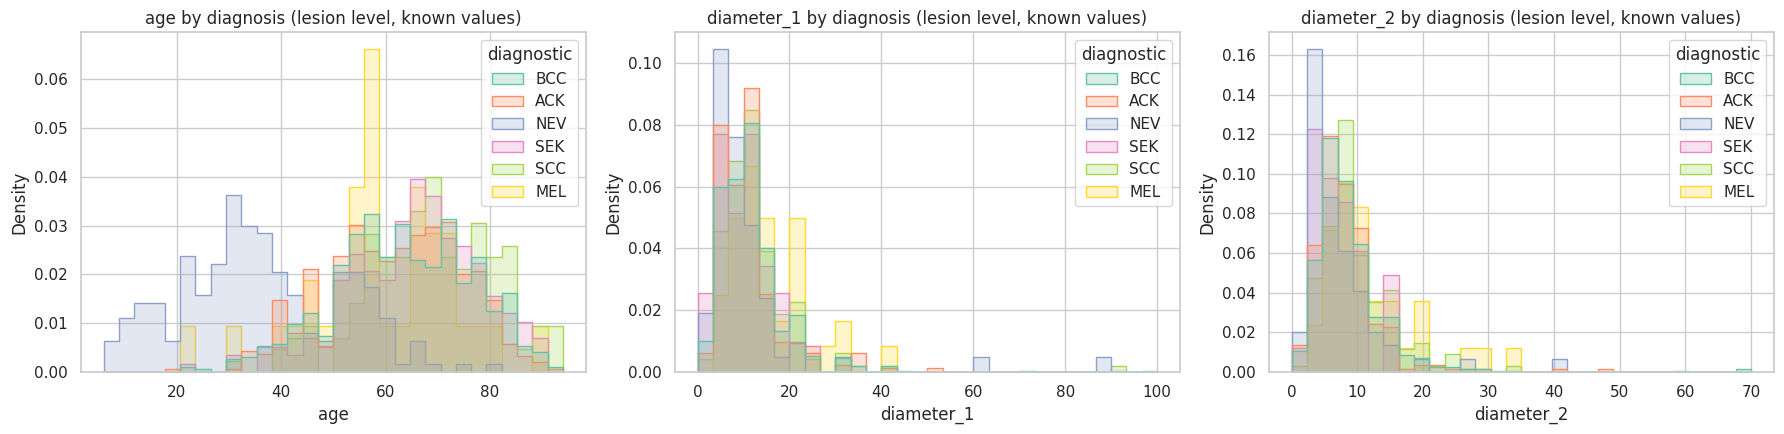

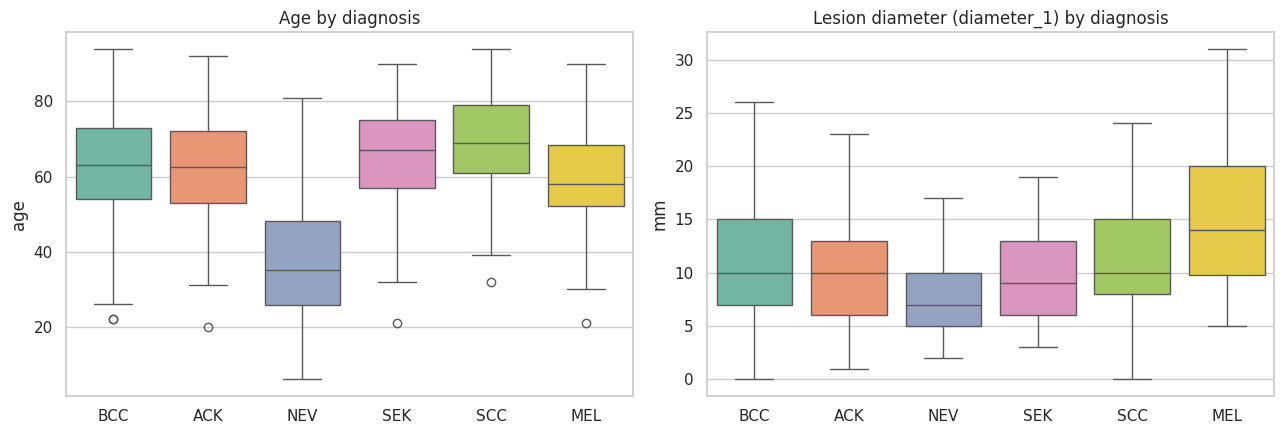

In [52]:
def desc(s): return pd.Series({"n": s.count(), "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(), "max": s.max()})
display(pd.DataFrame({c: desc(lesions[c]) for c in NUM}).T.round(2).rename_axis("overall (lesion level)"))
by_class = pd.concat({c: lesions.groupby(LABEL)[c].apply(desc).unstack().reindex(ORDER) for c in NUM}).round(2)
by_class.to_csv(FIG_DIR / "numeric_summary_by_class.csv")
display(by_class)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, c in zip(ax, ["age", "diameter_1", "diameter_2"]):
    sns.histplot(data=lesions.dropna(subset=[c]), x=c, hue=LABEL, hue_order=ORDER, palette=PAL, element="step",
                 stat="density", common_norm=False, bins=30, ax=a)
    a.set(title=f"{c} by diagnosis (lesion level, known values)")
finish("07_numeric_distributions_by_class")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=lesions, x=LABEL, y="age", order=ORDER, palette=PAL, ax=ax[0]); ax[0].set(title="Age by diagnosis", xlabel="")
sns.boxplot(data=lesions.dropna(subset=["diameter_1"]), x=LABEL, y="diameter_1", order=ORDER, palette=PAL, ax=ax[1], showfliers=False)
ax[1].set(title="Lesion diameter (diameter_1) by diagnosis", xlabel="", ylabel="mm")
finish("08_age_diameter_boxplots")

**Findings:**
- **Age:** mean 60.3, median 62 (range 6-94) - consistent with the ~60-year average mentioned in the dataset paper.
  By class: **NEV is much younger (mean 36.0)**; SEK 65.6, BCC 63.3, ACK 62.0, SCC 68.7, MEL 59.1.
- **Diameter** (questionnaire subset, 1,179 lesions): median `diameter_1` 10 mm, 95th percentile 25 mm, max 100 mm. MEL lesions are larger (mean 15.5 mm, median 14) than the other classes (median 7-10 mm).
- `fitspatrick`: mean 2.25; 95.6 % of known values are types 1-3.

**Potential consequences for model training:**
- Age is a genuinely informative feature (NEV vs. the rest) and available for all images.
- Use median imputation and robust scaling for diameters (heavy right tail, extreme values up to 100 mm).
- Diameter statistics rest on the selected questionnaire subset (mostly BCC/SCC/MEL) - class differences there are partly a selection effect.
- The population is a specific one (older patients, mostly light skin types), see Section 9: results need not transfer to other populations.

## 9. Categorical attributes: gender, body region, symptoms, skin type

**Description:**
- Which body regions occur, and how does the class mix differ between regions? Region may carry information that is not always visible in the image alone.
- Population context (from the dataset paper, per team notes): patients come from eleven cities in the Brazilian state of Espirito Santo, many are descendants of European immigrants, many work(ed) in agriculture with long sun exposure. The paper merged ~120 anatomical regions into 15 larger ones.

gender,FEMALE,MALE,MISSING
diagnostic,,,
BCC,311,341,0
ACK,135,113,396
NEV,41,22,153
SEK,22,13,163
SCC,71,74,0
MEL,19,17,0


lesions per region: {'FACE': 481, 'FOREARM': 338, 'CHEST': 215, 'BACK': 192, 'ARM': 153, 'NOSE': 128, 'HAND': 107, 'NECK': 71, 'EAR': 63, 'THIGH': 62, 'ABDOMEN': 30, 'LIP': 20, 'SCALP': 18, 'FOOT': 13}


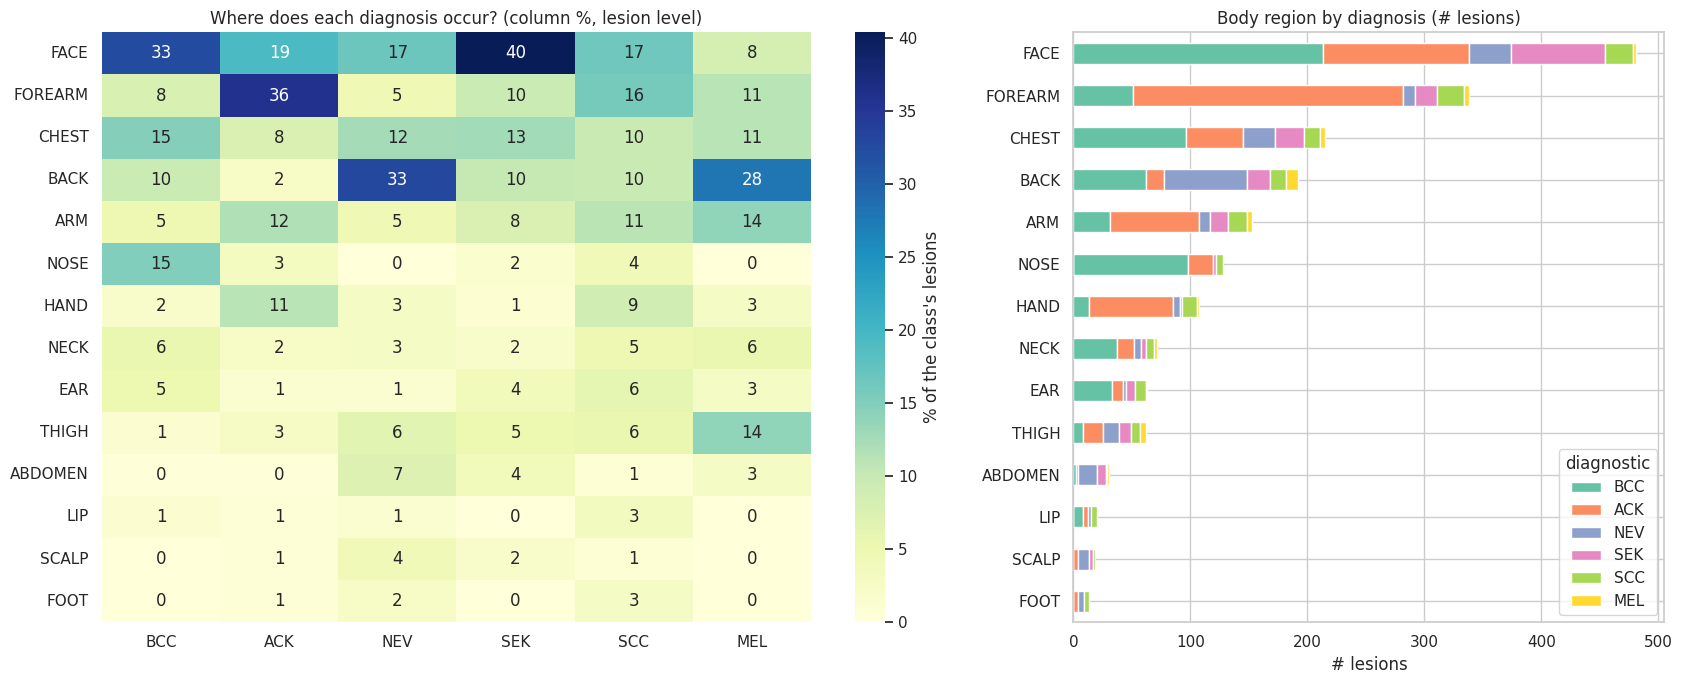

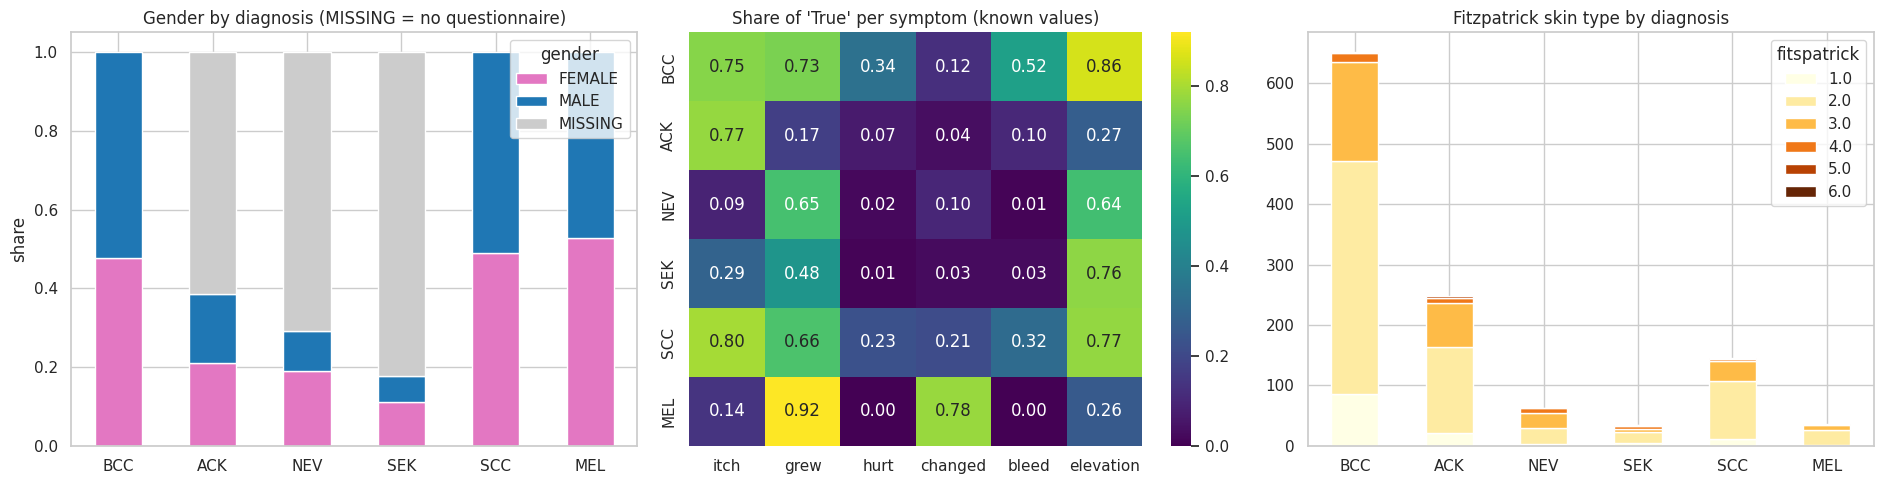

In [53]:
gt = pd.crosstab(lesions[LABEL], lesions.gender.fillna("MISSING")).reindex(ORDER)
display(gt)
rt = pd.crosstab(lesions.region, lesions[LABEL])[ORDER]; rt = rt.loc[rt.sum(axis=1).sort_values(ascending=False).index]
print("lesions per region:", rt.sum(axis=1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(100 * rt.div(rt.sum(axis=0), axis=1), annot=True, fmt=".0f", cmap="YlGnBu", ax=ax[0], cbar_kws={"label": "% of the class's lesions"})
ax[0].set(title="Where does each diagnosis occur? (column %, lesion level)", ylabel="", xlabel="")
rt.plot(kind="barh", stacked=True, ax=ax[1], color=[PAL[k] for k in ORDER]); ax[1].invert_yaxis()
ax[1].set(title="Body region by diagnosis (# lesions)", xlabel="# lesions", ylabel="")
finish("09_region_vs_label")

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
gt.div(gt.sum(axis=1), axis=0).plot(kind="bar", stacked=True, ax=ax[0], rot=0, color=["#e377c2", "#1f77b4", "#cccccc"])
ax[0].set(title="Gender by diagnosis (MISSING = no questionnaire)", ylabel="share", xlabel="")
tf = {"True": 1, "False": 0, True: 1, False: 0}
sym = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
heat = pd.DataFrame({c: lesions.assign(v=lesions[c].map(tf)).groupby(LABEL).v.mean() for c in sym}).reindex(ORDER)
sns.heatmap(heat, annot=True, fmt=".2f", cmap="viridis", ax=ax[1]); ax[1].set(title="Share of 'True' per symptom (known values)", ylabel="")
fz = pd.crosstab(lesions[LABEL], lesions.fitspatrick).reindex(ORDER)
fz.plot(kind="bar", stacked=True, ax=ax[2], colormap="YlOrBr", rot=0); ax[2].set(title="Fitzpatrick skin type by diagnosis", xlabel="")
finish("10_gender_symptoms_fitzpatrick")

**Findings:**
- **Regions (lesions):** FACE 481, FOREARM 338, CHEST 215, BACK 192, ARM 153, NOSE 128, HAND 107, NECK 71, EAR 63, THIGH 62, ABDOMEN 30, LIP 20, SCALP 18, FOOT 13 (14 distinct values in the CSV).
  The class mix differs clearly between regions (association `region` vs. diagnosis: Cramer's V = 0.28).
  Typical patterns (share of a class's lesions): ACK on the forearm 36 %, NEV on the back 33 %, MEL on the back 28 % and thigh 14 %, SEK on the face 40 %, BCC on the face 33 % and nose 15 %.
- **Gender:** roughly balanced where known (BCC 311 F / 341 M, SCC 71 / 74, MEL 19 / 17, ACK 135 / 113); for ACK/NEV/SEK most entries are missing (questionnaire batch).
- **Symptoms:** `elevation`, `itch`, `grew`, `bleed` and `hurt` differ strongly between classes (V = 0.38-0.53, see Section 10) - they are the most informative clinical features.
- **Fitzpatrick** (known values, lesion level): 95.6 % are types 1-3 (type 2: 58.9 %, type 3: 26.0 %, type 1: 10.8 %); only 4 % are types 4-6.

**Potential consequences for model training:**
- Body region is complete and informative -> a main candidate for modality 2. It also introduces dataset-specific correlations (e.g. BCC on the face) that a model may exploit without the image.
- Gender is mostly missing for the benign classes -> any gender effect is confounded with the batch; do not interpret it clinically.
- Symptom features are available for nearly all images and carry the strongest label signal; they are the natural "informative metadata" group for the secondary question.
- Population caveat: older, mostly lighter-skinned Brazilian patients with high sun exposure; conclusions about $\Delta U_{epi}$ are limited to this population.

## 10. Association of every feature with the diagnosis

**Description:**
- How strongly does each feature relate to the label (lesion level, one row per lesion)? Bias-corrected **Cramer's V** for binary/categorical features, **epsilon-squared** (Kruskal-Wallis H / (n-1)) for numeric features. Both range from 0 (no association) to 1 and are *roughly* comparable, not identical.
- Additionally: how strongly does the **missingness pattern itself** (`is missing` yes/no) relate to the label? This quantifies the shortcut risk.
- Only effect sizes are reported (no p-values): lesions of the same patient are not independent.

,feature,effect_measure,assoc_known_values,assoc_of_missingness,missing_%
0,biopsed,Cramer's V,0.801,0.000,0.0
1,elevation,Cramer's V,0.530,0.112,0.1
2,itch,Cramer's V,0.524,0.080,0.3
3,grew,Cramer's V,0.508,0.461,20.5
4,bleed,Cramer's V,0.500,0.037,0.3
5,hurt,Cramer's V,0.380,0.034,0.4
6,changed,Cramer's V,0.372,0.468,20.1
7,region,Cramer's V,0.281,0.000,0.0
8,age,epsilon^2,0.221,0.000,0.0
9,smoke,Cramer's V,0.124,0.699,37.7


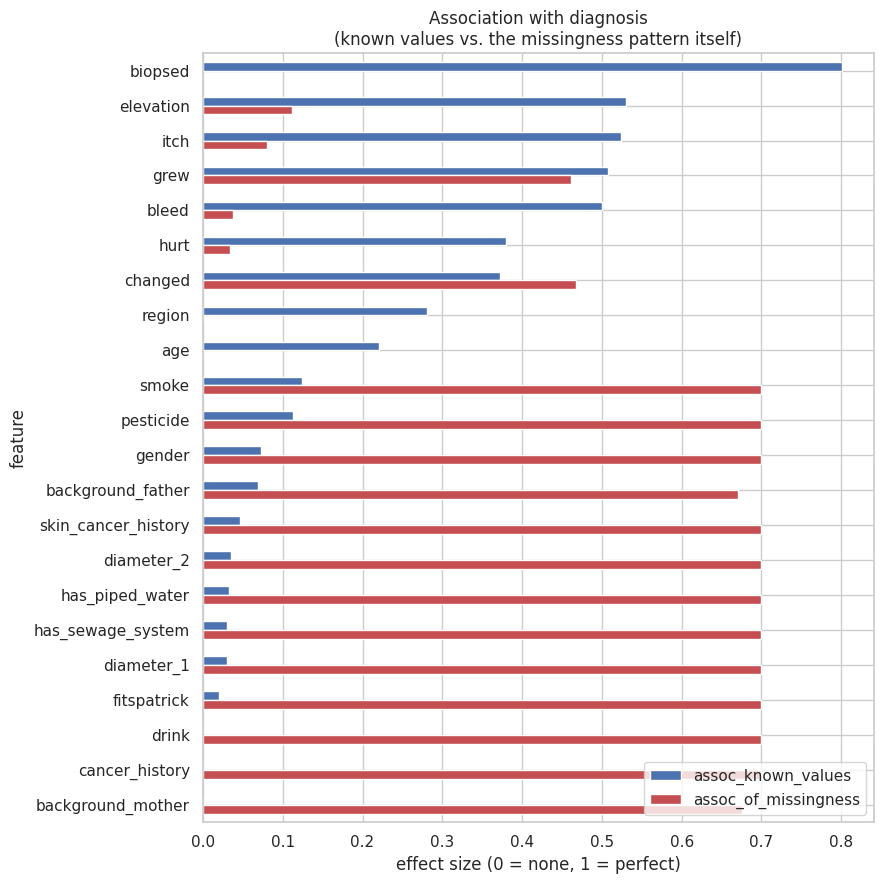

In [54]:
def cramers_v(x, y):
    """bias-corrected Cramer's V (Bergsma 2013)"""
    t = pd.crosstab(x, y)
    if t.shape[0] < 2 or t.shape[1] < 2: return 0.0
    chi2 = chi2_contingency(t, correction=False)[0]; n = t.values.sum(); r, k = t.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(kc - 1, rc - 1))) if min(kc, rc) > 1 else 0.0

res = []
for c in FEATS:
    obs = lesions.dropna(subset=[c])
    if c in NUM:
        H = kruskal(*[g[c].values for _, g in obs.groupby(LABEL)])[0]; eff = H / (len(obs) - 1); kind = "epsilon^2"
    else:
        eff = cramers_v(obs[c].astype(str), obs[LABEL]); kind = "Cramer's V"
    res.append((c, kind, round(eff, 3), round(cramers_v(lesions[c].isna(), lesions[LABEL]), 3), round(100 * lesions[c].isna().mean(), 1)))
ar = pd.DataFrame(res, columns=["feature", "effect_measure", "assoc_known_values", "assoc_of_missingness", "missing_%"]) \
       .sort_values("assoc_known_values", ascending=False).reset_index(drop=True)
ar.to_csv(FIG_DIR / "association_with_diagnosis.csv", index=False)
display(ar)

ar.set_index("feature")[["assoc_known_values", "assoc_of_missingness"]].plot(kind="barh", figsize=(9, 9), color=["#4c72b0", "#c44e52"])
plt.gca().invert_yaxis(); plt.legend(loc="lower right")
plt.title("Association with diagnosis\n(known values vs. the missingness pattern itself)"); plt.xlabel("effect size (0 = none, 1 = perfect)")
finish("11_association_with_diagnosis")

**Findings:**
- **`biopsed` is by far the strongest (V = 0.80)** -> leakage (Section 6).
- Informative clinical features (known values): `elevation` 0.53, `itch` 0.52, `grew` 0.51, `bleed` 0.50, `hurt` 0.38, `changed` 0.37; then `region` 0.28 and `age` 0.22 (epsilon^2).
- The questionnaire features have almost no signal in their *known values* (`smoke` 0.12, `pesticide` 0.11, `gender` 0.07, `background_father` 0.07, `skin_cancer_history` 0.04, `diameter_2`/`diameter_1`/`has_piped_water`/`has_sewage_system` ~0.03, `fitspatrick` 0.02, `drink`, `cancer_history`, `background_mother` ~0), but **whether they are missing relates strongly to the diagnosis (V ~ 0.70)**. For `grew`/`changed` the missingness V is ~0.46.

**Potential consequences for model training:**
- The informative/weak split for the secondary question: *informative* = symptoms + region + age; *weak* = most questionnaire features.
- For the weak questionnaire features the only "signal" a model can find is the **missingness shortcut**, so a $\Delta U_{epi}$ difference driven by them would not reflect clinical information.
- Report the missing-indicator arm separately (Section 12).

## 11. Candidate features for modality 2

**Description:**
- Excluded from the start: identifiers (`patient_id`, `lesion_id`, `img_id`/filenames), the diagnosis field and `biopsed`.
- For each remaining feature: type, missing rate, association with the label, and whether its missingness tracks the class.
- The tiers below are rule-of-thumb cut-offs (0.10 / 0.30), **not** a statistical test.

In [55]:
CAND = [c for c in FEATS if c != "biopsed"]
sel = ar[ar.feature.isin(CAND)].copy()
sel["type"] = sel.feature.map(lambda c: "numeric" if c in NUM else ("binary" if c in BIN else "categorical"))
sel["tier"] = pd.cut(sel.assoc_known_values, [-1, 0.10, 0.30, 2], labels=["weak (<0.10)", "moderate (0.10-0.30)", "strong (>0.30)"])
sel["missingness_tracks_class"] = sel.assoc_of_missingness > 0.30
sel = sel[["feature", "type", "missing_%", "assoc_known_values", "tier", "assoc_of_missingness", "missingness_tracks_class"]]
sel.to_csv(FIG_DIR / "candidate_features_modality2.csv", index=False)
display(sel)
print("features always available (<5% missing):", [c for c in CAND if df[c].isna().mean() < 0.05])

,feature,type,missing_%,assoc_known_values,tier,assoc_of_missingness,missingness_tracks_class
1,elevation,binary,0.1,0.530,strong (>0.30),0.112,False
2,itch,binary,0.3,0.524,strong (>0.30),0.080,False
3,grew,binary,20.5,0.508,strong (>0.30),0.461,True
4,bleed,binary,0.3,0.500,strong (>0.30),0.037,False
5,hurt,binary,0.4,0.380,strong (>0.30),0.034,False
6,changed,binary,20.1,0.372,strong (>0.30),0.468,True
7,region,categorical,0.0,0.281,moderate (0.10-0.30),0.000,False
8,age,numeric,0.0,0.221,moderate (0.10-0.30),0.000,False
9,smoke,binary,37.7,0.124,moderate (0.10-0.30),0.699,True
10,pesticide,binary,37.7,0.113,moderate (0.10-0.30),0.699,True


features always available (<5% missing): ['itch', 'hurt', 'bleed', 'elevation', 'region', 'age']


**Findings:**
- 21 candidate features. **Strong:** the 6 symptoms (`elevation`, `itch`, `grew`, `bleed`, `hurt`, `changed`). **Moderate:** `region`, `age`, `smoke`, `pesticide`. **Weak:** the rest.
- Always available (<5 % missing): `age`, `region`, `itch`, `hurt`, `bleed`, `elevation`.
- **15 of the 21 candidates** have missingness that tracks the class (the 11-feature questionnaire block, `background_father/mother`, `grew`, `changed`). Only `age`, `region` and the four symptoms `itch`, `hurt`, `bleed`, `elevation` do not.

**Potential consequences for model training:**
- A clean "informative metadata" set = symptoms + `region` + `age`; a "weak metadata" set = the questionnaire features. This maps directly onto the secondary research question.
- Decide before modelling whether weak features are used with or without missing indicators (confound!).

## 12. Tabular-only baseline (how much signal is in the metadata alone?)

**Description:**
- Train simple tabular models on the metadata only, with **patient-grouped 5-fold CV** (`StratifiedGroupKFold`, groups = `patient_id`), imputation fitted *inside* each training fold, class-balanced sample weights, no tuning.
- Feature sets: A all candidates (median/mode imputation); B = A + missing indicators; C only always-available features; D = A + `biopsed` (leakage demo); E only the 1-bit flag "questionnaire present?".
- Purpose: tells us whether the metadata carries signal; **it says nothing about uncertainty**.

,feature_set,model,macro_F1,balanced_acc,accuracy,log_loss,MEL_recall
0,"A: all candidates, imputed, no indicators",logreg,0.568,0.632,0.628,1.014,0.654
1,"A: all candidates, imputed, no indicators",hgb,0.554,0.552,0.667,1.201,0.385
2,B: A + missing indicators,logreg,0.588,0.642,0.661,0.898,0.615
3,B: A + missing indicators,hgb,0.574,0.570,0.700,1.123,0.385
4,C: only always-available features,logreg,0.495,0.548,0.575,1.148,0.404
5,C: only always-available features,hgb,0.440,0.453,0.564,1.463,0.096
6,D: A + biopsed (leakage demo),logreg,0.603,0.668,0.666,0.895,0.692
7,D: A + biopsed (leakage demo),hgb,0.580,0.577,0.705,1.087,0.385
8,E: ONLY 'questionnaire present?' (1 binary fea...,logreg,0.121,0.301,0.174,1.479,0.808
9,E: ONLY 'questionnaire present?' (1 binary fea...,hgb,0.147,0.303,0.186,1.477,0.615


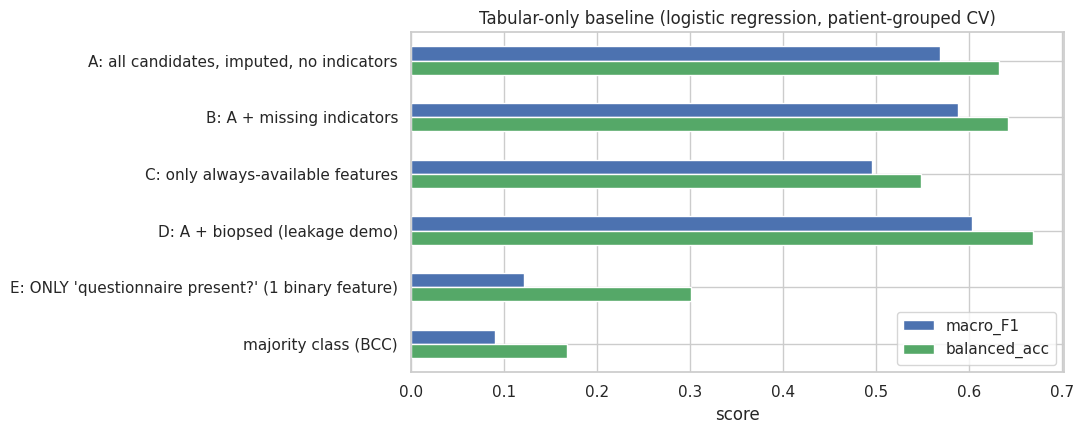

In [56]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score, log_loss, recall_score

classes = sorted(df[LABEL].unique())
def build_X(cols, indicators=False):
    X = pd.DataFrame(index=df.index)
    for c in cols:
        if c in NUM: X[c] = df[c].astype(float)
        else: X[c] = df[c].map(lambda v: np.nan if pd.isna(v) else str(v)).astype(object)
        if indicators and df[c].isna().any(): X[c + "__missing"] = df[c].isna().map({True: "1", False: "0"}).astype(object)
    return X

def make_pipe(X, model):
    num = [c for c in X.columns if c in NUM]; cat = [c for c in X.columns if c not in NUM]
    tr = []
    if num: tr.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num))
    if cat: tr.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat))
    clf = LogisticRegression(max_iter=3000) if model == "logreg" else HistGradientBoostingClassifier(random_state=0)
    return Pipeline([("pre", ColumnTransformer(tr)), ("clf", clf)])

always = [c for c in CAND if df[c].isna().mean() < 0.05]
SETS = {
    "A: all candidates, imputed, no indicators": (CAND, False),
    "B: A + missing indicators": (CAND, True),
    "C: only always-available features": (always, False),
    "D: A + biopsed (leakage demo)": (CAND + ["biopsed"], False),
}
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(df, df[LABEL], df.patient_id))
y = df[LABEL].values; rows = []

def evaluate(name, model, X):
    P = np.zeros((len(df), len(classes))); pred = np.empty(len(df), dtype=object)
    for tr, te in folds:
        pipe = make_pipe(X, model)
        pipe.fit(X.iloc[tr], y[tr], clf__sample_weight=compute_sample_weight("balanced", y[tr]))
        P[te] = pipe.predict_proba(X.iloc[te]); pred[te] = pipe.classes_[P[te].argmax(1)]
    rows.append(dict(feature_set=name, model=model, macro_F1=f1_score(y, pred, average="macro"),
                     balanced_acc=balanced_accuracy_score(y, pred), accuracy=accuracy_score(y, pred),
                     log_loss=log_loss(y, P, labels=classes), MEL_recall=recall_score(y, pred, labels=["MEL"], average=None)[0]))

for name, (cols, ind) in SETS.items():
    for model in ["logreg", "hgb"]: evaluate(name, model, build_X(cols, ind))
Xq = pd.DataFrame({"has_questionnaire": df.has_clinical.map({True: "1", False: "0"}).astype(object)})
for model in ["logreg", "hgb"]: evaluate("E: ONLY 'questionnaire present?' (1 binary feature)", model, Xq)
maj = np.array(["BCC"] * len(df))
rows.append(dict(feature_set="majority class (BCC)", model="-", macro_F1=f1_score(y, maj, average="macro"),
                 balanced_acc=balanced_accuracy_score(y, maj), accuracy=accuracy_score(y, maj), log_loss=np.nan, MEL_recall=0.0))
baseline = pd.DataFrame(rows).round(3); baseline.to_csv(FIG_DIR / "tabular_baseline.csv", index=False)
display(baseline)

b2 = baseline[baseline.model.isin(["logreg", "-"])].set_index("feature_set")[["macro_F1", "balanced_acc"]]
b2.plot(kind="barh", figsize=(11, 4.5), color=["#4c72b0", "#55a868"]); plt.gca().invert_yaxis()
plt.title("Tabular-only baseline (logistic regression, patient-grouped CV)"); plt.xlabel("score"); plt.ylabel("")
finish("12_tabular_baseline")

**Findings:**
- Out-of-fold predictions pooled over 5 patient-grouped folds, untuned (a rough indication, not a benchmark). Logistic regression (balanced accuracy): see table above; headline values: majority class 0.17, all candidates imputed **0.63**, + missing indicators **0.64**, only the 1-bit "questionnaire present?" flag **0.30**, + `biopsed` **0.67**.
- The metadata **alone carries real signal** (far above the majority baseline).
- The missingness flag alone is only a modest shortcut (it essentially separates the late batch from the rest).
- Only the always-available features (`age`, `region`, 4 symptoms) reach balanced accuracy 0.55.
- `biopsed` adds little on top (0.67 vs 0.63).
- Gradient boosting is worse than logistic regression in balanced accuracy, macro-F1 and log loss here (its higher plain accuracy comes mostly from the large classes).

**Potential consequences for model training:**
- A $\Delta U_{epi}$ of exactly 0 should **not** be the default expectation: the metadata is informative, so the fusion model *can* learn from it.
- Start with logistic-regression-like tabular encoders; they are more stable than boosting at this sample size.
- Keep `biopsed` out (cheap to exclude, high leakage risk); run the missing-indicator variant as its own arm.
- These numbers are about classification only - uncertainty must be measured separately with the actual image/fusion networks.

## 13. Plausibility and conflicts (basis for the "corrupted metadata" experiments)

**Description:**
- Implausible values and conflicting entries in the metadata, and attributes that should be constant for a patient but are not.
- This informs how clean vs. corrupted/conflicting metadata can be constructed for the secondary question.

In [57]:
print(f"age: min {lesions.age.min()}, max {lesions.age.max()} | under 18: {int((lesions.age < 18).sum())} | over 90: {int((lesions.age > 90).sum())}")
for c in ["diameter_1", "diameter_2"]:
    print(f"{c}: median {lesions[c].median()}, 95th pct {lesions[c].quantile(.95)}, max {lesions[c].max()} | >=30 mm: {int((lesions[c] >= 30).sum())}")
both = lesions[["diameter_1", "diameter_2"]].dropna()
print("lesions with diameter_2 > diameter_1:", int((both.diameter_2 > both.diameter_1).sum()), "of", len(both), "with both diameters known")

PATIENT_LEVEL = ["gender", "age", "smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history", "has_piped_water",
                 "has_sewage_system", "background_father", "background_mother", "fitspatrick"]
multi_les = lesions.groupby("patient_id").filter(lambda g: len(g) > 1)
inc = {c: int((multi_les.groupby("patient_id")[c].nunique() > 1).sum()) for c in PATIENT_LEVEL}
print(f"\npatient-level attributes that differ between lesions of the SAME patient (patients with >1 lesion: {multi_les.patient_id.nunique()}):")
display(pd.Series(inc, name="# patients with conflicting values").to_frame())

age: min 6, max 94 | under 18: 29 | over 90: 10
diameter_1: median 10.0, 95th pct 25.0, max 100.0 | >=30 mm: 43
diameter_2: median 7.0, 95th pct 18.0, max 70.0 | >=30 mm: 13
lesions with diameter_2 > diameter_1: 14 of 1179 with both diameters known

patient-level attributes that differ between lesions of the SAME patient (patients with >1 lesion: 355):


,# patients with conflicting values
gender,0
age,90
smoke,0
drink,0
pesticide,0
skin_cancer_history,0
cancer_history,0
has_piped_water,0
has_sewage_system,0
background_father,0


**Findings:**
- `age` ranges 6-94 (29 lesions under 18, 10 over 90); `diameter_1` reaches 100 mm (43 lesions >= 30 mm); **14 of 1,179** lesions have `diameter_2` > `diameter_1`.
- Patient-level attributes (gender, smoking, histories, water, sewage, Fitzpatrick, background) **never conflict** between lesions of the same patient. Only `age` differs, for 90 of 355 multi-lesion patients (probably different visit dates - our assumption).

**Potential consequences for model training / experiments:**
- The data is internally consistent, so "conflicting metadata" must be **constructed** for the corrupted arm. Corrupt per lesion (all images of a lesion get the same change), restricted to the informative features (symptoms, `age`, `region`).
- Options: permute one feature across patients; swap whole metadata rows between patients of different classes; add noise to `age` and diameters. Decide on the protocol before running experiments.
- Obvious outliers (diameter 100 mm, `diameter_2` > `diameter_1`) should be kept but handled robustly (median imputation, robust scaling) - they are rare.

## 14. Patient-grouped 5-fold CV preview and rare-class budget

**Description:**
- How are classes spread across test folds with `StratifiedGroupKFold` (groups = `patient_id`)? This shows how coarse the per-class uncertainty statistics will be.
- The check also verifies that no patient appears in both train and test of the same fold.

images per fold: {0: 460, 1: 460, 2: 459, 3: 460, 4: 459} | no patient in train and test of the same fold: OK


images per test fold                     patients per test fold                    
fold                          0    1    2    3    4                      0    1    2    3    4
diagnostic                                                                                    
BCC                         169  169  169  169  169                    103  104  101  104  101
ACK                         146  146  146  146  146                    104  103  105  106  107
NEV                          49   49   49   49   48                     37   37   37   37   37
SEK                          47   47   47   47   47                     35   35   37   35   34
SCC                          39   38   38   38   39                     28   26   26   25   28
MEL                          10   11   10   11   10                      7    8    7    8    6

smallest number of test patients per class over folds: {'BCC': 101, 'ACK': 103, 'NEV': 37, 'SEK': 34, 'SCC': 25, 'MEL': 6}


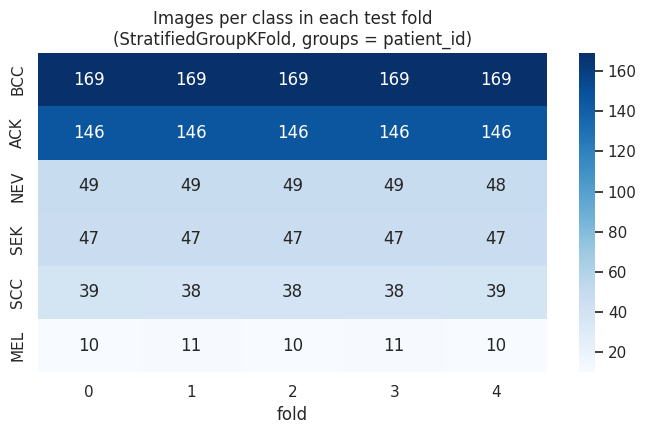

In [58]:
fold = pd.Series(-1, index=df.index)
for k, (tr, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(df, df[LABEL], df.patient_id)):
    assert not (set(df.iloc[tr].patient_id) & set(df.iloc[te].patient_id)), "patient in train and test!"
    fold.iloc[te] = k
fi = pd.crosstab(df[LABEL], fold.rename("fold")).reindex(ORDER)
fp = df.groupby([LABEL, fold]).patient_id.nunique().unstack(fill_value=0).reindex(ORDER)
print("images per fold:", fold.value_counts().sort_index().to_dict(), "| no patient in train and test of the same fold: OK")
display(pd.concat({"images per test fold": fi, "patients per test fold": fp}, axis=1))
print("smallest number of test patients per class over folds:", fp.min(axis=1).to_dict())
pd.DataFrame({"img_id": df.img_id, "fold": fold}).to_csv(FIG_DIR / "fold_assignment_preview.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5)); sns.heatmap(fi, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set(title="Images per class in each test fold\n(StratifiedGroupKFold, groups = patient_id)", xlabel="fold", ylabel="")
finish("13_cv_fold_preview")

**Findings:**
- No patient appears in train and test of the same fold (asserted).
- **MEL: 10-11 images per test fold from only 6-8 patients**; fewest test patients per class over folds: MEL 6, SCC 25, SEK 34, NEV 37, BCC 101, ACK 103.

**Potential consequences for model training:**
- Per-class $\Delta U_{epi}$ for MEL (and to a lesser degree SCC) will be very coarse. **Pool predictions across folds** and report **patient-level bootstrap intervals**; do not interpret rare-class uncertainty as precise.
- Fix the fold assignment (seed 42, saved in `figures/fold_assignment_preview.csv`) so that image-only and image+metadata models are evaluated on identical splits - $\Delta U_{epi}$ is a paired comparison.
- Compute image-level metrics but aggregate to lesion/patient level before any statistical comparison.

## 15. Image inspection: file inventory, sizes, colour modes

**Description:**
- The three image folders (`data/imgs_part_1..3`) are scanned. For every image the header and a 256x256 thumbnail are used to compute: width, height, colour mode, file size, brightness, sharpness (variance of the Laplacian), mean RGB, blue/purple "ink" fraction and a perceptual hash. Results are cached in `figures/image_properties.csv` (delete the file to recompute).
- Questions: how different are the sizes? Are all images square? RGB or RGBA? Do sizes/brightness differ systematically between classes? Do the three folders differ in class mix?
- The dataset paper states that image sizes differ because different smartphone devices were used (the CSV itself contains no device information).
- **Cells in Sections 15-17 only produce output if images are present in `../data/imgs_part_*`.**

In [59]:
IMG_PATHS, FOLDER_OF = {}, {}
for d_ in sorted(DATA.glob("imgs_part_*")):
    for p in sorted(d_.glob("*.png")):
        if p.name in IMG_PATHS: print("WARNING: file name appears in several folders:", p.name)
        IMG_PATHS[p.name] = p; FOLDER_OF[p.name] = d_.name
HAVE_IMGS = len(IMG_PATHS) > 0
df["folder"] = df.img_id.map(FOLDER_OF)
print("images found:", len(IMG_PATHS), "| in metadata:", int(df.img_id.isin(IMG_PATHS).sum()),
      "| without metadata row:", len(set(IMG_PATHS) - set(df.img_id)), "| metadata rows without image:", int((~df.img_id.isin(IMG_PATHS)).sum()))
if HAVE_IMGS:
    display(pd.crosstab(df[LABEL], df.folder).reindex(ORDER).rename_axis("class \\ folder"))
    print("patient-number range per folder:\n", df.groupby("folder").patient_num.agg(["min", "max"]).to_string())
    multi_f = df.dropna(subset=["folder"]).groupby("patient_id").folder.nunique()
    print("patients with images in more than one folder:", int((multi_f > 1).sum()), "-> never split by folder, always by patient_id")

images found: 2298 | in metadata: 2298 | without metadata row: 0 | metadata rows without image: 0


folder,imgs_part_1,imgs_part_2,imgs_part_3
class \ folder,,,
BCC,540,305,0
ACK,167,180,383
NEV,41,36,167
SEK,33,24,178
SCC,108,84,0
MEL,22,30,0


patient-number range per folder:
               min   max
folder                 
imgs_part_1     8   585
imgs_part_2   587  1093
imgs_part_3  1094  2162
patients with images in more than one folder: 0 -> never split by folder, always by patient_id


  reading images 0/2298 ...
  reading images 250/2298 ...
  reading images 500/2298 ...
  reading images 750/2298 ...
  reading images 1000/2298 ...
  reading images 1250/2298 ...
  reading images 1500/2298 ...
  reading images 1750/2298 ...
  reading images 2000/2298 ...
  reading images 2250/2298 ...


,w,h,short_side,MB
count,2298.0,2298.0,2298.0,2298.0
mean,933.7,933.6,933.4,1.6
std,534.6,534.7,534.7,1.8
min,147.0,147.0,147.0,0.0
25%,528.0,527.2,527.2,0.4
50%,779.5,779.5,779.5,1.0
75%,1219.2,1218.8,1218.5,2.1
max,3474.0,3476.0,3474.0,23.6


share exactly square: 0.816 | aspect ratio min/max: 0.888 / 1.157 | distinct (w, h) sizes: 1450
colour modes: {'RGBA': 1440, 'RGB': 858}
downscale factor to 224 px (short_side / 224): median 3.5, min 0.7, max 15.5


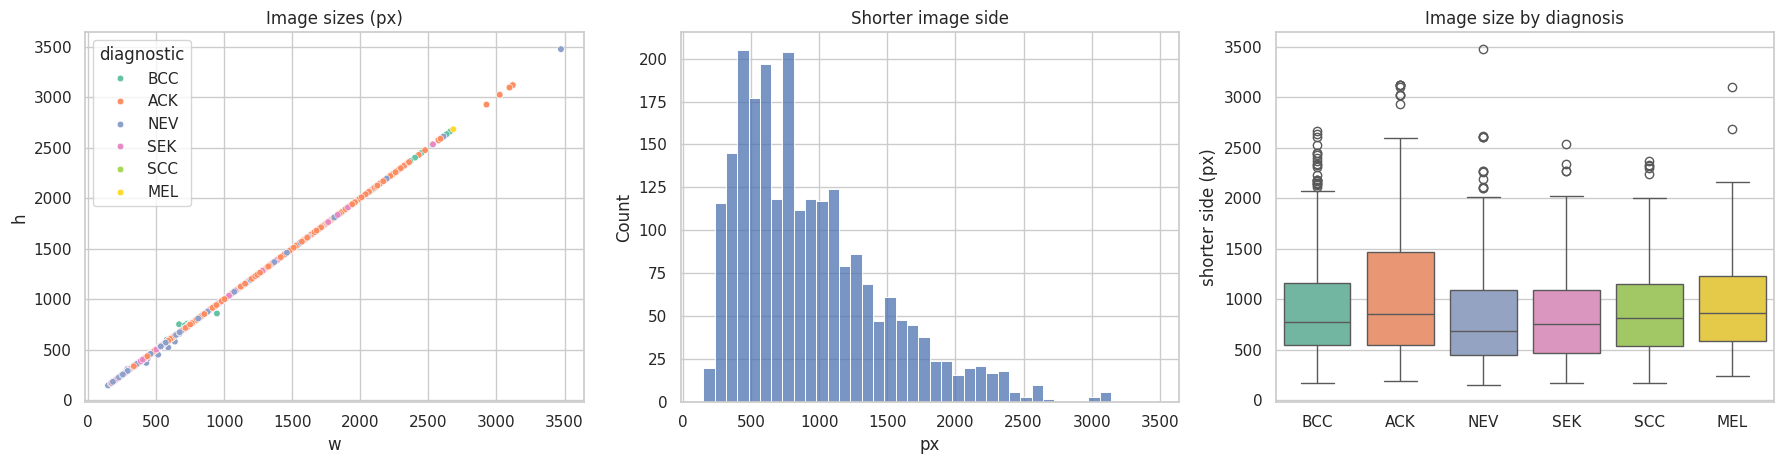

In [60]:
H_LO, H_HI, S_MIN, V_MIN, THR = 120, 215, 25, 40, 0.005     # blue/purple ink heuristic, calibrated on only 6 images (Section 16)

def image_stats(p):
    with Image.open(p) as im:
        w, h, mode = im.width, im.height, im.mode
        t = im.convert("RGB").resize((256, 256), Image.BILINEAR)
    a = np.asarray(t).astype(np.float32); gray = 0.299 * a[..., 0] + 0.587 * a[..., 1] + 0.114 * a[..., 2]
    lap = 4 * gray[1:-1, 1:-1] - gray[:-2, 1:-1] - gray[2:, 1:-1] - gray[1:-1, :-2] - gray[1:-1, 2:]
    hsv = np.asarray(t.convert("HSV"))
    ink = ((hsv[..., 0] >= H_LO) & (hsv[..., 0] <= H_HI) & (hsv[..., 1] >= S_MIN) & (hsv[..., 2] >= V_MIN)).mean()
    g17 = np.asarray(t.convert("L").resize((17, 16), Image.LANCZOS), dtype=np.int16)      # dHash 16x16 = 256 bits
    dh = np.packbits((g17[:, 1:] > g17[:, :-1]).flatten()).tobytes().hex()
    return dict(w=w, h=h, mode=mode, MB=os.path.getsize(p) / 1e6, brightness=gray.mean(), sharpness=lap.var(), ink_fraction=ink,
                R=a[..., 0].mean(), G=a[..., 1].mean(), B=a[..., 2].mean(), dhash=dh, md5=hashlib.md5(open(p, "rb").read()).hexdigest())

sz = None
if HAVE_IMGS:
    cache = FIG_DIR / "image_properties.csv"
    if cache.exists() and set(pd.read_csv(cache).img_id) == set(IMG_PATHS):
        sz = pd.read_csv(cache)
    else:
        recs = []
        for i, (b, p) in enumerate(IMG_PATHS.items()):
            if i % 250 == 0: print(f"  reading images {i}/{len(IMG_PATHS)} ...")
            recs.append(dict(img_id=b, folder=FOLDER_OF[b], **image_stats(p)))
        sz = pd.DataFrame(recs).merge(df[["img_id", LABEL, "patient_id", "lesion_id", "region"]], on="img_id", how="left")
        sz["short_side"] = sz[["w", "h"]].min(axis=1); sz["aspect"] = sz.w / sz.h; sz["marked"] = sz.ink_fraction > THR
        sz.to_csv(cache, index=False)
    display(sz[["w", "h", "short_side", "MB"]].describe().round(1))
    print("share exactly square:", round((sz.w == sz.h).mean(), 3), "| aspect ratio min/max:", round(sz.aspect.min(), 3), "/", round(sz.aspect.max(), 3),
          "| distinct (w, h) sizes:", sz[["w", "h"]].drop_duplicates().shape[0])
    print("colour modes:", sz["mode"].value_counts().to_dict())
    print("downscale factor to 224 px (short_side / 224): median %.1f, min %.1f, max %.1f" % ((sz.short_side / 224).median(), (sz.short_side / 224).min(), (sz.short_side / 224).max()))

    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    sns.scatterplot(data=sz, x="w", y="h", hue=LABEL, hue_order=ORDER, palette=PAL, s=22, ax=ax[0]); ax[0].set(title="Image sizes (px)")
    sns.histplot(sz.short_side, bins=40, ax=ax[1], color="#4c72b0"); ax[1].set(title="Shorter image side", xlabel="px")
    sns.boxplot(data=sz, x=LABEL, y="short_side", order=ORDER, palette=PAL, ax=ax[2]); ax[2].set(title="Image size by diagnosis", xlabel="", ylabel="shorter side (px)")
    finish("14_image_sizes")

**Findings:** *(fill in after running with the full image folders - the tables above give the numbers)*
- *Size range (min / median / max of the shorter side), share of exactly square images, aspect-ratio range, number of distinct sizes:* ___
- *Colour modes (RGB vs. RGBA), file-size range:* ___
- *Do sizes differ between classes or between folders?* ___
- Preliminary (only 6 sample images, one per class, from `imgs_part_1`): all nearly square (681 x 681 up to 1325 x 1325 px; one image is 926 x 927), mixed RGB/RGBA, 0.4-2.9 MB. **This is not a statement about the whole dataset.**

**Potential consequences for model training:**
- Resize all images to a fixed input size (e.g. 224 x 224, or larger if the backbone allows) with a consistent interpolation, and **convert to RGB** (drop the alpha channel) at load time.
- Images are downscaled by a large factor (several x for 224 px): choose the resolution consciously, so diagnostically relevant detail is not lost. Fit normalisation statistics on training folds only.
- If sizes differ systematically between classes, image size / file size could act as a shortcut -> check the boxplot above before choosing preprocessing (e.g. always resize + re-encode).

## 16. Image appearance: brightness, sharpness, colour, example images

**Description:**
- Look at the data. 4 random images per class, plus per-class distributions of brightness, sharpness (variance of the Laplacian on a 256 px thumbnail) and mean colour.
- Things to look for: partly covered lesions, hair, marker rings, different lighting, blurry images, and different body regions (nose, ears, lips).

median per class:


,short_side,MB,brightness,sharpness,R,G,B
diagnostic,,,,,,,
BCC,771.0,1.1,142.899994,102.199997,169.000000,133.399994,120.500000
ACK,855.0,1.1,140.699997,110.400002,167.199997,132.300003,116.400002
NEV,690.0,0.6,144.100006,39.200001,164.500000,138.199997,120.300003
SEK,756.0,0.8,144.000000,99.800003,165.699997,137.000000,120.400002
SCC,815.0,1.2,137.600006,105.500000,168.699997,130.199997,118.400002
MEL,860.0,1.0,137.699997,59.099998,154.800003,130.199997,122.300003


median per folder:


,short_side,MB,brightness,sharpness
folder,,,,
imgs_part_1,750.0,0.9,140.699997,101.099998
imgs_part_2,822.0,1.1,144.399994,91.099998
imgs_part_3,859.0,0.9,141.600006,97.900002


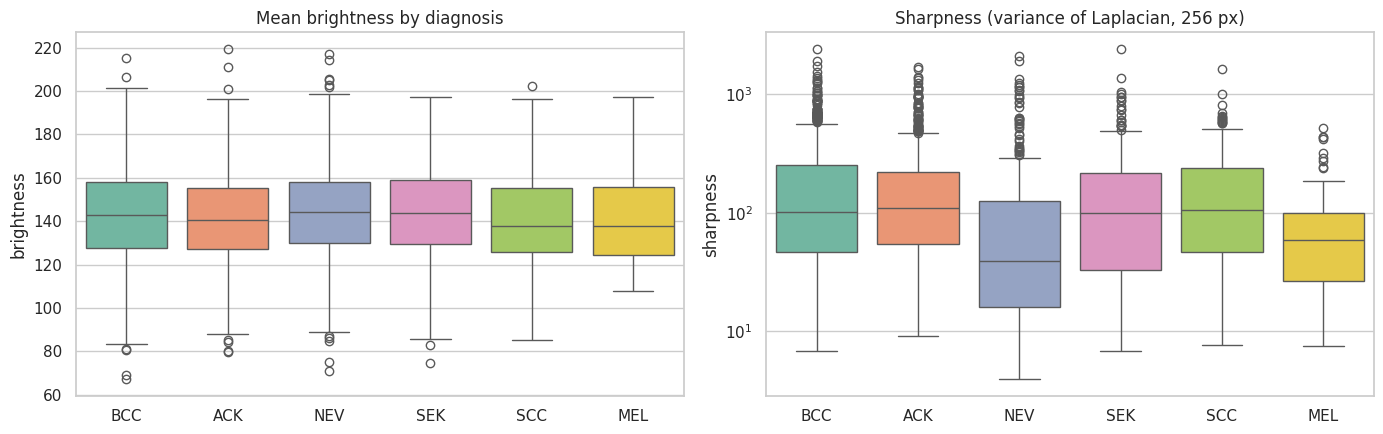

In [61]:
if HAVE_IMGS:
    print("median per class:")
    display(sz.groupby(LABEL)[["short_side", "MB", "brightness", "sharpness", "R", "G", "B"]].median().reindex(ORDER).round(1))
    print("median per folder:"); display(sz.groupby("folder")[["short_side", "MB", "brightness", "sharpness"]].median().round(1))
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    sns.boxplot(data=sz, x=LABEL, y="brightness", order=ORDER, palette=PAL, ax=ax[0]); ax[0].set(title="Mean brightness by diagnosis", xlabel="")
    sns.boxplot(data=sz, x=LABEL, y="sharpness", order=ORDER, palette=PAL, ax=ax[1]); ax[1].set(title="Sharpness (variance of Laplacian, 256 px)", xlabel="", yscale="log")
    finish("15_brightness_sharpness_by_class")

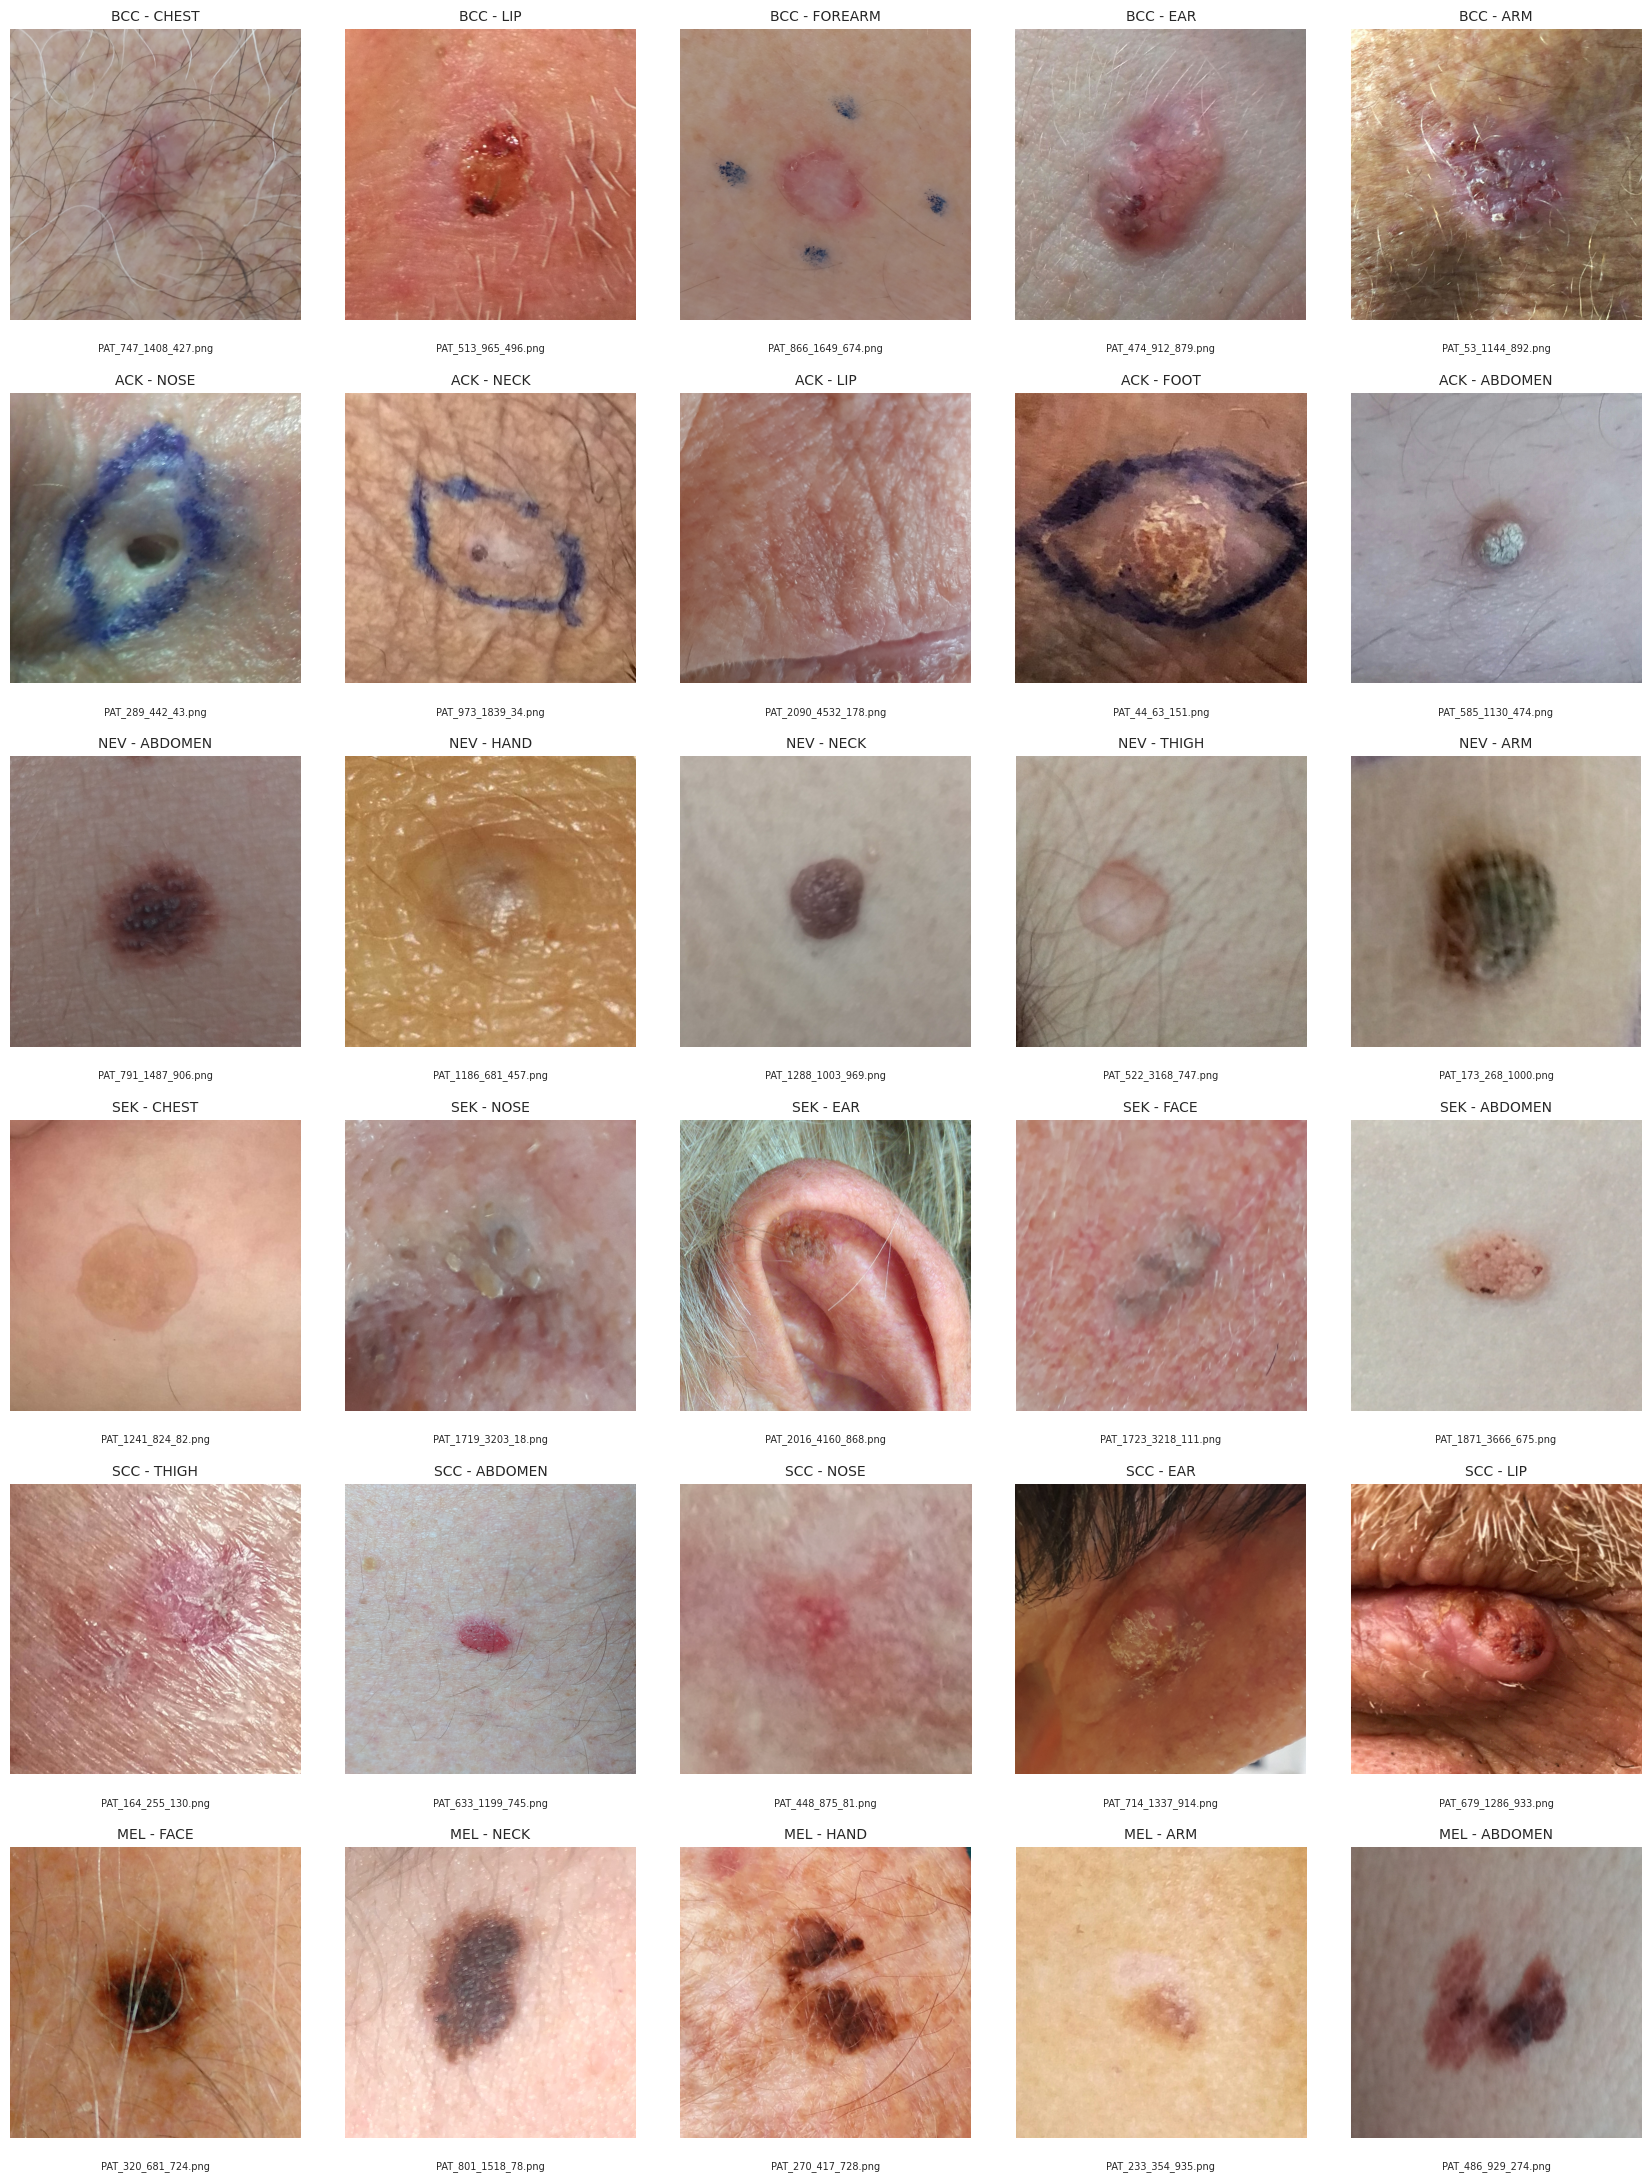

In [62]:
if HAVE_IMGS:
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(6, 5, figsize=(17, 22))

    meta = df.set_index("img_id")

    for r_, cls in enumerate(ORDER):

        # Only images belonging to the current class
        class_data = sz[sz[LABEL] == cls]

        # Select up to 5 different regions
        regions = class_data["img_id"].map(meta["region"])
        available_regions = regions.dropna().unique()

        selected_regions = rng.choice(
            available_regions,
            size=min(5, len(available_regions)),
            replace=False
        )

        for c_ in range(5):
            a = axes[r_, c_]
            a.axis("off")

            if c_ < len(selected_regions):
                region = selected_regions[c_]

                # Select an image from the current class and region
                candidates = class_data[
                    class_data["img_id"].map(meta["region"]) == region
                ]["img_id"].tolist()

                img_id = rng.choice(candidates)

                # Verify the class and region
                assert meta.loc[img_id, LABEL] == cls
                assert meta.loc[img_id, "region"] == region

                a.imshow(Image.open(IMG_PATHS[img_id]).convert("RGB"))
                a.set_title(f"{cls} - {region}", fontsize=10)
                a.text(
                    0.5, -0.08, img_id,
                    transform=a.transAxes,
                    ha="center",
                    va="top",
                    fontsize=7
                )

    plt.tight_layout()
    finish("16_example_images_grid")

**Findings:** *(fill in after looking at the grid and the distributions on the full data)*
- *Brightness / sharpness differences between classes or folders:* ___
- *Visible artefacts (hair, partly covered lesions, blur, strong lighting differences):* ___
- Preliminary observation (6 sample images, one per class): purple marker rings drawn around the lesion were visible in some images (e.g. BCC, NEV, SEK); the lesion fills different fractions of the frame; skin tone, lighting and background texture differ visibly. One image per class cannot show a distribution.

**Potential consequences for model training:**
- Augmentation (random rotation, flips, small crops/scaling, mild brightness/contrast) to cover the different appearances and lighting.
- Hair: removal techniques or augmentation if needed; hair and body region (nose, ears) are normal variation and need no special handling unless a class is strongly tied to one region (Section 9 shows region/class links).
- Not measured here: hair coverage, partial occlusion (add manual columns to the labelling sheet in Section 17 if relevant).

## 17. Marker rings (possible shortcut) and duplicate images

**Description:**
- Some images show blue/purple pen markings around the lesion. The metadata contains **no** information on this; it has to be derived from the images.
- Risk: if rings occur more often in some classes, a CNN can learn "ring -> class" instead of the lesion. Then the image-only model's uncertainty (and with it $\Delta U_{epi}$) would partly reflect this artefact.
- Two tools: (a) a **colour heuristic** (blue/purple pixels, thresholds calibrated on 6 images only - it already *missed a faint ring* in the NEV sample, so treat rates as lower bounds and check by eye); (b) a **manual labelling sheet** (30 random images per class) whose filled version gives reliable per-class rates and the heuristic's sensitivity/specificity.

blue/purple marker HEURISTIC per class (misses faint rings - verify by eye!):


,mean,sum,count
diagnostic,,,
BCC,0.173,146,845
ACK,0.122,89,730
NEV,0.160,39,244
SEK,0.102,24,235
SCC,0.172,33,192
MEL,0.365,19,52


marked share per class x folder:


folder,imgs_part_1,imgs_part_2,imgs_part_3
diagnostic,,,
BCC,0.178,0.164,NaN
ACK,0.198,0.106,0.097
NEV,0.268,0.306,0.102
SEK,0.091,0.208,0.090
SCC,0.213,0.119,NaN
MEL,0.273,0.433,NaN


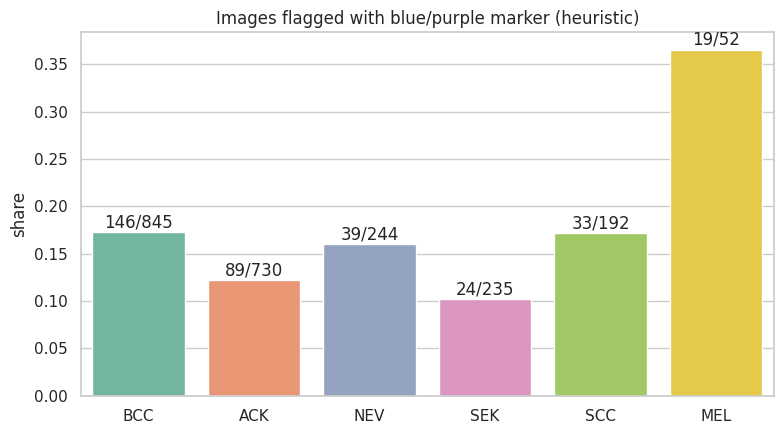

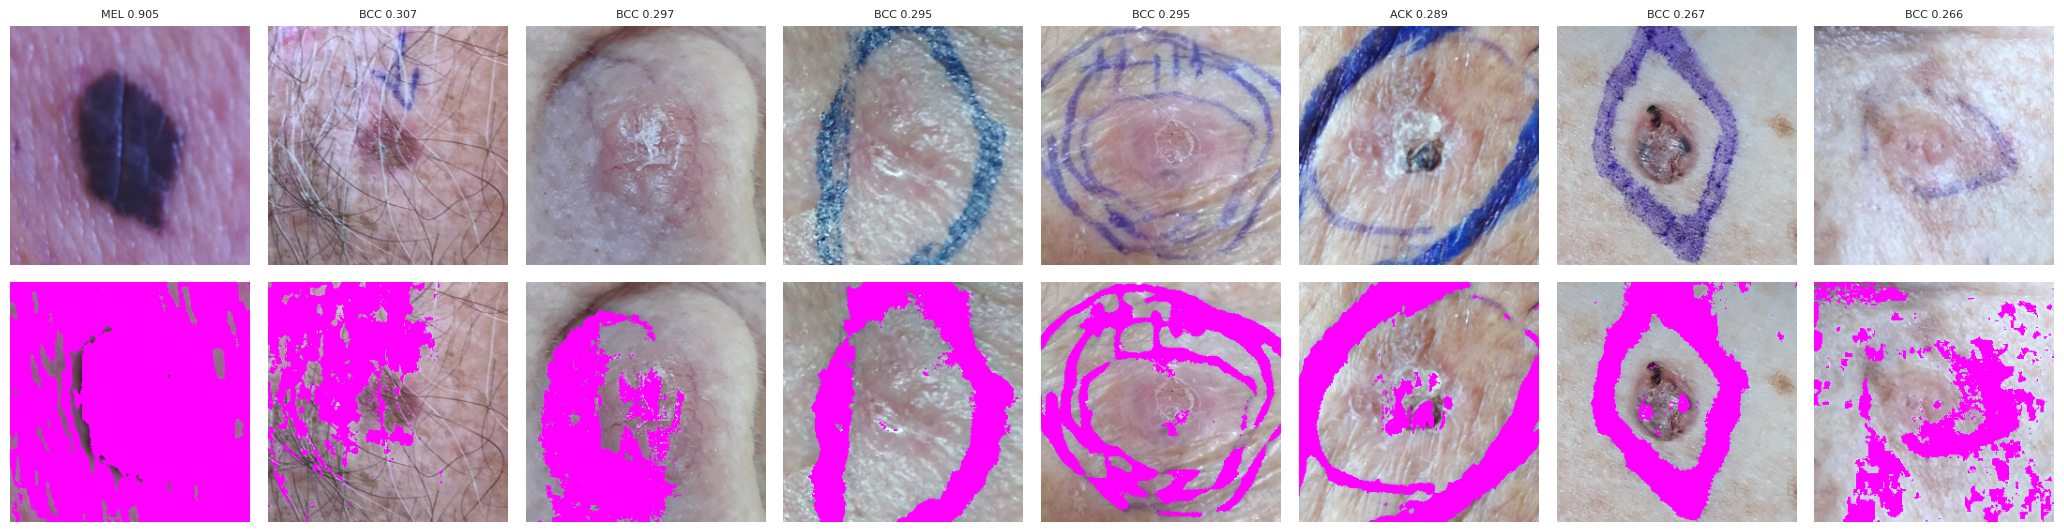

In [63]:
if HAVE_IMGS:
    mk = sz.groupby(LABEL).marked.agg(["mean", "sum", "count"]).reindex(ORDER)
    print("blue/purple marker HEURISTIC per class (misses faint rings - verify by eye!):"); display(mk.round(3))
    print("marked share per class x folder:"); display(sz.pivot_table(index=LABEL, columns="folder", values="marked", aggfunc="mean").reindex(ORDER).round(3))

    fig, ax = plt.subplots(figsize=(8, 4.5)); m2 = mk["mean"].fillna(0)
    sns.barplot(x=m2.index, y=m2.values, palette=[PAL[k] for k in m2.index], ax=ax)
    for i, (r_, n_) in enumerate(zip(mk["sum"].fillna(0), mk["count"].fillna(0))): ax.text(i, m2.values[i] + 0.005, f"{int(r_)}/{int(n_)}", ha="center")
    ax.set(title="Images flagged with blue/purple marker (heuristic)", ylabel="share", xlabel="")
    finish("17_marker_rate_by_class")

    # visual check: the 8 most strongly flagged images with the detected pixels painted magenta
    top = sz.sort_values("ink_fraction", ascending=False).head(8)
    fig, axes = plt.subplots(2, len(top), figsize=(2.6 * len(top), 5.6), squeeze=False)
    for j, r_ in enumerate(top.itertuples()):
        t = Image.open(IMG_PATHS[r_.img_id]).convert("RGB").resize((256, 256)); a = np.asarray(t).copy(); hsv = np.asarray(t.convert("HSV"))
        m = (hsv[..., 0] >= H_LO) & (hsv[..., 0] <= H_HI) & (hsv[..., 1] >= S_MIN) & (hsv[..., 2] >= V_MIN); ov = a.copy(); ov[m] = [255, 0, 255]
        axes[0, j].imshow(a); axes[1, j].imshow(ov); axes[0, j].set_title(f"{getattr(r_, LABEL)} {r_.ink_fraction:.3f}", fontsize=8)
        for ax_ in axes[:, j]: ax_.axis("off")
    finish("18_marker_overlay_check")

In [13]:
if HAVE_IMGS:
    # manual labelling sheet: 30 random images per class. Fill 'ring_manual' (1/0) and optionally 'hair_manual' while looking at the images,
    # save as figures/marker_labeling_sheet_filled.csv and re-run this cell.
    sheet = pd.concat([g.sample(min(30, len(g)), random_state=0) for _, g in sz.groupby(LABEL)])[["img_id", "folder", LABEL, "marked"]] \
              .rename(columns={"marked": "heuristic_marked"})
    sheet["ring_manual"] = ""; sheet["hair_manual"] = ""
    sheet.to_csv(FIG_DIR / "marker_labeling_sheet.csv", index=False)
    filled = FIG_DIR / "marker_labeling_sheet_filled.csv"
    if filled.exists():
        m = pd.read_csv(filled).dropna(subset=["ring_manual"]); m["ring_manual"] = m.ring_manual.astype(int)
        print("MANUAL ring labels per class:"); display(m.groupby(LABEL).ring_manual.agg(["mean", "sum", "count"]).reindex(ORDER).round(3))
        if "hair_manual" in m and m.hair_manual.notna().any():
            print("MANUAL hair labels per class:"); display(m.dropna(subset=["hair_manual"]).groupby(LABEL).hair_manual.agg(["mean", "sum", "count"]).reindex(ORDER).round(3))
        tp = ((m.heuristic_marked) & (m.ring_manual == 1)).sum(); fn = ((~m.heuristic_marked) & (m.ring_manual == 1)).sum()
        fp_ = ((m.heuristic_marked) & (m.ring_manual == 0)).sum(); tn = ((~m.heuristic_marked) & (m.ring_manual == 0)).sum()
        print(f"heuristic vs manual: sensitivity {tp/max(tp+fn,1):.2f}, specificity {tn/max(tn+fp_,1):.2f}")
    else:
        print(f"labelling sheet written to {FIG_DIR/'marker_labeling_sheet.csv'} - fill it in to get reliable ring rates per class")

labelling sheet written to figures/marker_labeling_sheet.csv - fill it in to get reliable ring rates per class


In [29]:
# ---- duplicate check, metadata level (runs without images) ----
feat_cols = [c for c in df.columns if c in raw.columns and c != "img_id"]
print("rows identical in ALL columns except img_id:", int(raw.drop(columns="img_id").duplicated(keep=False).sum()),
      "(= the", int(per_les[per_les > 1].sum()), "images of multi-image lesions)")
k = df.groupby(["patient_id", "region", LABEL]).lesion_id.nunique()
print("patient+region+diagnosis groups with >1 lesion_id (possibly the same lesion under two IDs):", int((k > 1).sum()))

# ---- duplicate check, image level: exact (MD5) and near duplicates (dHash, Hamming distance <= THR_DUP of 256 bits) ----
THR_DUP = 20
if HAVE_IMGS:
    ex = sz.groupby("md5").img_id.apply(list); ex = ex[ex.map(len) > 1]
    print("\ngroups of byte-identical files:", len(ex))
    Hb = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in sz.dhash])
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    names = sz.img_id.values; found = []
    for i0 in range(0, len(names), 200):
        dist = POP[Hb[i0:i0 + 200, None, :] ^ Hb[None, :, :]].sum(-1)
        ii, jj = np.where(dist <= THR_DUP)
        found += [(a_ + i0, b_, int(dist[a_, b_])) for a_, b_ in zip(ii, jj) if b_ > a_ + i0]
    npairs = pd.DataFrame(found, columns=["i", "j", "dist"])
    if len(npairs):
        meta = sz.set_index("img_id")
        npairs["a"], npairs["b"] = names[npairs.i], names[npairs.j]
        for c_ in ["patient_id", "lesion_id", LABEL]:
            npairs[c_ + "_a"], npairs[c_ + "_b"] = meta.loc[npairs.a, c_].values, meta.loc[npairs.b, c_].values
        npairs["same_patient"] = npairs.patient_id_a == npairs.patient_id_b
        npairs["same_lesion"] = npairs.same_patient & (npairs.lesion_id_a == npairs.lesion_id_b)
        npairs["diff_label"] = npairs[LABEL + "_a"] != npairs[LABEL + "_b"]
        npairs.drop(columns=["i", "j"]).sort_values("dist").to_csv(FIG_DIR / "near_duplicate_pairs.csv", index=False)
        print(f"near-duplicate pairs (distance <= {THR_DUP}/256): {len(npairs)} | same lesion: {int(npairs.same_lesion.sum())} | "
              f"same patient, other lesion: {int((npairs.same_patient & ~npairs.same_lesion).sum())} | DIFFERENT patients: {int((~npairs.same_patient).sum())} | different label: {int(npairs.diff_label.sum())}")
        cross = npairs[~npairs.same_patient].sort_values("dist").head(4)
        if len(cross):
            fig, axes = plt.subplots(len(cross), 2, figsize=(7, 3.6 * len(cross)), squeeze=False)
            for r_, row in enumerate(cross.itertuples()):
                for c_, nm in enumerate([row.a, row.b]):
                    axes[r_, c_].imshow(Image.open(IMG_PATHS[nm]).convert("RGB")); axes[r_, c_].axis("off")
                    axes[r_, c_].set_title(f"{nm[:18]}\n{meta.loc[nm, LABEL]}  (dist {row.dist})", fontsize=8)
            finish("19_closest_cross_patient_pairs")
    else:
        print(f"no near-duplicate pairs at distance <= {THR_DUP}/256")

rows identical in ALL columns except img_id: 768 (= the 768 images of multi-image lesions)
patient+region+diagnosis groups with >1 lesion_id (possibly the same lesion under two IDs): 106

groups of byte-identical files: 15
near-duplicate pairs (distance <= 20/256): 16 | same lesion: 0 | same patient, other lesion: 16 | DIFFERENT patients: 0 | different label: 13


**Findings:**
- **Metadata level (verified):** the 768 images of the 361 multi-image lesions have identical metadata except `img_id` - these are the "duplicates" that matter for splitting. 106 patient+region+diagnosis groups contain more than one `lesion_id` (possibly the same lesion under different IDs); grouping by `patient_id` covers this automatically.
- **Marker rings (to fill in after the full run + manual labels):** *rate per class (heuristic): ___; rate per class (manual, 30 images per class): ___; heuristic sensitivity/specificity: ___*. Preliminary: rings seen in single examples of BCC, NEV and SEK - **no distribution can be derived from 6 images**; the colour heuristic is calibrated on those 6 and missed one faint ring.
- **Image level (to fill in after the full run):** exact duplicates (MD5): ___; near-duplicate pairs: ___ (same lesion ___, other lesion of the same patient ___, different patients ___; inspect the closest cross-patient pairs by eye - the distance threshold of 20/256 bits is only a starting guess).

**Potential consequences for model training:**
- If ring rates differ clearly between classes: **robustness experiment** (e.g. centre crop that cuts off most of the ring, or inpainting the ring) and report image-only uncertainty with and without it. Do not remove rings from the training data up front.
- Duplicates across different patients would leak even with a patient-grouped split -> if found, merge those patients into one group for the split.
- Patient-grouped splits already handle same-lesion and same-patient repeats.

## 18. Summary: findings, challenges, approach

| Finding | Challenge | Our approach |
|---|---|---|
| Class imbalance (16.2 : 1); MEL 2.3 % (52 images, 36 lesions/patients) | Rare-class training and very coarse rare-class uncertainty statistics | Class weighting / oversampling / focal loss (to verify); **Macro-F1 and balanced accuracy**; per-class $\Delta U_{epi}$ with pooled folds and patient-level bootstrap; no precise claims for MEL |
| Multiple images per lesion (361 lesions, 768 images), multiple lesions per patient (355 patients), 179 patients with several diagnoses | Leakage between train and test; non-independent observations | **Patient-grouped 5-fold CV** (`StratifiedGroupKFold`, seed 42), never `lesion_id` alone; lesion-level statistics |
| 1,641 `lesion_id` values vs. 1,891 `(patient_id, lesion_id)` pairs (250 shared IDs) | Wrong lesion counts / wrong grouping | Use the pair as lesion key; state both numbers |
| Questionnaire missing for 35 % of images, only in patient batch >= 996 (ACK/NEV/SEK); BCC/SCC/MEL always complete | Missingness reveals the class (shortcut, V ~ 0.70) | Impute inside each training fold (median / `unknown`); **missing-indicator arm as separate experiment**; keep patient number out of the features |
| `biopsed` is 100 % True for BCC/SCC/MEL (V = 0.80) | Label leakage | **Exclude `biopsed`** from modality 2 |
| Informative features: symptoms (V 0.37-0.53), `region` 0.28, `age` 0.22; most questionnaire features weak (V <= 0.12) | Which metadata to use; informative vs. weak split | Informative set = symptoms + region + age; weak set = questionnaire features |
| Metadata alone gives balanced accuracy ~0.63 (patient-grouped CV) | Metadata is informative -> $\Delta U_{epi} = 0$ is not the default expectation | Interpret $\Delta U_{epi}$ against this; run corrupted-metadata arm (permute/swap/noise on informative features) |
| Images differ in size / colour mode (preliminary: 6 images only) | Different resolutions, RGBA vs. RGB | Convert to RGB, fixed-size resize (check detail loss), augmentation; fill in Section 15 after the full run |
| Marker rings, hair, lighting (not yet quantified) | Possible image shortcut | Quantify with manual labels (Section 17); robustness experiment if rates differ by class |

**Open items after running on the full image folders**
1. Fill in the `___` findings in Sections 15-17 (sizes, brightness, ring rates, duplicates).
2. Label the marker sheet (30 images per class) and re-run Section 17.
3. Inspect the closest near-duplicate pairs from different patients.
4. Decide the corruption protocol and the missing-indicator policy before training.
5. Optional: use the second dataset (held out for validation) only after the main experiments.

**Preprocessing reminders:** images -> RGB, fixed size (e.g. 224 x 224), normalise with training-fold statistics; metadata -> normalise numeric, one-hot categorical with `unknown`, median imputation, all fitted per training fold; `biopsed`, IDs and filenames never as features.

## 19. Other papers

**DermaCalibra: A Robust and Explainable Multimodal Framework for Skin Lesion Diagnosis via Bayesian Uncertainty and Dynamic Modulation:**

Steps:
- Resized input images to 224 × 224 pixels.
- Normalized images using ImageNet mean and standard deviation values.
- Median imputation to missing numerical metadata, "Unknown" for missing categorical metadata.
- Encoded clinical metadata into an 81-dimensional feature representation and applied metadata regularization using Batch Normalization, ReLU and Dropout (p = 0.5) before multimodal fusion to reduce overfitting.
- Used Monte Carlo Dropout to estimate predictive uncertainty, introduced the Attention-Based Multimodal Channel Recalibration (AMCR) module and dynamically adjusted focal-loss weights to give more attention to underrepresented classes.

Discoveries:
- SCC achieved the lowest sensitivity in the PAD-UFES-20 evaluation (56.3%) (misclassified as BCC)
    Reasons: similar visual characteristics, important distinguishing features are difficult to capture with standard RGB smartphone cameras, SCC has substantially fewer training examples than BCC but clinical metadata (age, lesion location) similar for both classes
Approach in DermaCalibra:
- Used metadata-driven dynamic feature modulation and cross-attention fusion (MDFM-CAF).

https://doi.org/10.3390/diagnostics16040630



**Evaluation of Boosting Algorithms for Skin Cancer Classification Using the PAD-UFES-20 Dataset and Custom CNN Feature Extraction**

Steps:
- Extracted image features using ConvMixer.
- Combined image features with patient metadata (age, gender and anatomical site).
- Compared three boosting classifiers: CatBoost, XGBoost and LightGBM.
- Applied data augmentation, normalization and Borderline-SMOTE to address class imbalance.
- Used patient-level data splitting to prevent data leakage.
- Evaluated performance using macro-AUC, macro-F1, sensitivity and Brier score.
- Used Grad-CAM and SHAP for model interpretability.

Discoveries:
- Classification errors mainly occurred between visually similar lesion classes.
- Age and region imbalances influenced model performance.

https://doi.org/10.3390/engproc2025087115




**TIP: Tabular-Image Pre-training for Multimodal Classification with Incomplete Data**

- Developed TIP, a self-supervised multimodal pre-training framework combining image and tabular data.
- Used a CNN-based image encoder (ResNet-50) and a Transformer-based tabular encoder.
- Processed categorical and continuous features separately.
- Represented missing values using a learnable special [MSK] token instead of applying conventional imputation.
- Used cross-modal attention to learn interactions between image and tabular representations.
- Applied three self-supervised pre-training tasks:
    - Masked Tabular Reconstruction (MTR): Reconstructed masked tabular features using image and remaining tabular information.
    - Image-Tabular Contrastive Learning (ITC): Aligned image and tabular representations from matching samples.
    - Image-Tabular Matching (ITM): Predicted whether an image and tabular data belonged to the same sample.
- Used an ensemble of three classifiers during fine-tuning, averaging their predictions.
 	
https://doi.org/10.48550/arXiv.2407.07582

